# Phase 3: Asset-Pricing Tests

## Objective
Phase 2 built the five Fama-French factors (MKT, SMB, HML, RMW, CMA) for the Nifty 500 universe. This phase tests whether those factors actually **explain the cross-section of Indian stock returns**, following the method of Fama & French (2015).

## Inputs
- `phase_2_ff5_factors.csv`: monthly factor returns and Rf (Jul-2016 onwards)
- `monthly_panel.csv`: monthly stock returns, market equity, formation dates
- `characteristic_annual.csv`: annual size, B/M, operating profitability, asset growth

## Steps
1. **Factor diagnostics**: average premium, volatility, t-stats and correlations of each factor; spanning regressions to check whether any factor (e.g., HML) is redundant.
2. **Test portfolios**: Size × B/M, Size × OP and Size × Investment sorts (3×3), formed every June, held July to June, value-weighted. These use the same rules and filters as Phase 2.
3. **Time-series regressions**: each portfolio's excess return is regressed on the five factors:

   $$R_p - R_f = a + b\,MKT + s\,SMB + h\,HML + r\,RMW + c\,CMA + e$$

   If the model is correct, every intercept $a$ should be zero.
4. **Model evaluation**: GRS test, average |a|, average R², and a comparison of CAPM, FF-3 and FF-5.

## Outputs
- **Tables**: factor summary, correlations, spanning regressions, test portfolio returns and holdings, regression results, residuals, model comparison. These are saved as `.csv` files plus one combined `phase_3_results.xlsx`.
- **Plots**: cumulative factor returns, rolling premia, correlation heatmap, intercept and loading heatmaps, and model-comparison charts. These are saved in `plots/phase_3/`.

## Limitations
- The sample is short, about 120 months, so the GRS test has low power. Failing to reject does not prove the model is correct.
- A 500-stock universe gives thin portfolios, so we use 3×3 sorts instead of FF's 5×5 and report stock counts per portfolio.

## Next
The regression results, residuals and portfolio holdings saved here feed **Phase 4**, which covers robustness and validation and later **Phase 5** covers stock and fund attribution and alpha screening.

In [1]:
# ==========================================================
# STEP 0: Imports + Paths and Previous Files
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

import statsmodels.api as sm        # OLS regressions with Newey-West errors
from scipy import stats             # F-distribution for the GRS test
import matplotlib.pyplot as plt     # all plots
import seaborn as sns               # heatmaps

PROJECT_ROOT = Path().resolve().parent

# Methodology constants (must match Phase 2)
BP_LOW = 0.30       # low breakpoint (30th percentile)
BP_HIGH = 0.70      # high breakpoint (70th percentile)
FORM_MONTH = 6      # June snapshot
MIN_STOCKS = 5      # min stocks per portfolio-month (documented deviation)

# Phase 3 constants
NW_LAGS = 6                 # Newey-West lags for monthly data
DATE_FORMAT = "%Y-%m-%d"     # date format used in the saved CSVs
MODELS = {
    "CAPM": ["MKT"],
    "FF3":  ["MKT", "SMB", "HML"],
    "FF5":  ["MKT", "SMB", "HML", "RMW", "CMA"],
}

# Input paths
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

FACTORS_FILE = PROCESSED_DIR / "phase_2_ff5_factors.csv"
PANEL_FILE = PROCESSED_DIR / "monthly_panel.csv"
CHAR_FILE = PROCESSED_DIR / "characteristics_annual.csv"

# Output paths
OUTPUT_DIR = PROCESSED_DIR                          # Phase 3 CSVs and xlsx saved here
PLOTS_DIR = PROJECT_ROOT / "plots" / "phase_3"      # Phase 3 PNG plots saved here
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Plot settings
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

# Quick check that all input files exist
for f in [FACTORS_FILE, PANEL_FILE, CHAR_FILE]:
    print(f.name, "->", "found" if f.exists() else "MISSING")

phase_2_ff5_factors.csv -> found
monthly_panel.csv -> found
characteristics_annual.csv -> found


In [2]:
# ==========================================================
# STEP 1: Factor diagnostics
# ==========================================================

In [3]:
# 1.1 data check

df_factors = pd.read_csv(
    FACTORS_FILE,
    parse_dates=["date"],   # convert the date column to real dates
    index_col="date",       # use it as the index
)
df_factors = df_factors.sort_index()

print(type(df_factors.index))   # should print DatetimeIndex

df_factors.head()

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


,MKT,SMB,HML,RMW,CMA,Rf
date,,,,,,
2016-07-31,0.060709,0.005808,-0.012576,0.007178,-0.013623,0.005668
2016-08-31,0.015503,0.013244,0.032281,0.001315,-0.012844,0.005504
2016-09-30,-0.084114,0.061957,0.111785,-0.033550,0.072281,0.005469
2016-10-31,-0.021765,0.084601,0.075787,-0.009725,-0.021774,0.005449
2016-11-30,-0.047348,-0.034959,-0.010143,-0.019812,0.029774,0.005306


In [4]:
print(df_factors.shape)
print(df_factors.describe())
print('First month:', df_factors.index.min().date())
print('Last month:', df_factors.index.max().date())
print(df_factors.isnull().sum())

(120, 6)
              MKT         SMB         HML         RMW         CMA          Rf
count  120.000000  120.000000  120.000000  120.000000  120.000000  120.000000
mean     0.004465    0.012983    0.008405   -0.002365    0.000849    0.004671
std      0.050751    0.035368    0.041716    0.033082    0.026172    0.001044
min     -0.223508   -0.088470   -0.096021   -0.098891   -0.067953    0.002546
25%     -0.022440   -0.007624   -0.015289   -0.018410   -0.016445    0.004219
50%      0.005671    0.012600    0.004070   -0.000334    0.000607    0.005102
75%      0.036051    0.034426    0.034589    0.013082    0.016473    0.005463
max      0.133127    0.098116    0.111785    0.109055    0.072281    0.005860
First month: 2016-07-31
Last month: 2026-06-30
MKT    0
SMB    0
HML    0
RMW    0
CMA    0
Rf     0
dtype: int64


In [5]:
# 1.2 computing mean monthly premium

FACTOR_COLS = ["MKT", "SMB", "HML", "RMW", "CMA"]   # Rf is not a factor

n_months = len(df_factors)

mean_premium = df_factors[FACTOR_COLS].mean()           # average monthly return
std_premium = df_factors[FACTOR_COLS].std()             # monthly volatility
t_stat = mean_premium / (std_premium / np.sqrt(n_months))   # is the mean different from zero?

factor_summary = pd.DataFrame({
    "mean_monthly_%": mean_premium * 100,
    "std_monthly_%": std_premium * 100,
    "t_stat": t_stat,
    "mean_annual_%": mean_premium * 12 * 100,
    "sharpe_annual": (mean_premium / std_premium) * np.sqrt(12),
    "n_months": n_months,
})

factor_summary.round(2)

,mean_monthly_%,std_monthly_%,t_stat,mean_annual_%,sharpe_annual,n_months
MKT,0.45,5.08,0.96,5.36,0.30,120
SMB,1.30,3.54,4.02,15.58,1.27,120
HML,0.84,4.17,2.21,10.09,0.70,120
RMW,-0.24,3.31,-0.78,-2.84,-0.25,120
CMA,0.08,2.62,0.36,1.02,0.11,120


***Interpretation***
* MKT: Rm-Rf returns of 0.45% monthly
* SMB: Small- Big returns of 1.30% monthly ... and so on for other factors
* t_stat tells us that SMB and HML are significant compared to other factors as, values > 2
* Sharpe annual values > 0.6 tells us that, High B/M companies have consistently beaten Low B/M companies

- **Sharpe ratio (annual):** $\text{Sharpe} = \dfrac{\text{mean monthly premium}}{\text{monthly std}} \times \sqrt{12}$
- **Link to the t-stat:** Over the same sample, $t \approx \text{Sharpe} \times \sqrt{\text{number of years}}$. With 10 years of data, $t \approx \text{Sharpe} \times 3.16$, so a factor needs a Sharpe of about **0.63** to reach $t = 2$. This is why some factors show a decent premium but still fail the significance test.

In [6]:
factor_summary.to_csv(OUTPUT_DIR / "phase_3_factor_summary.csv")

<Axes: >

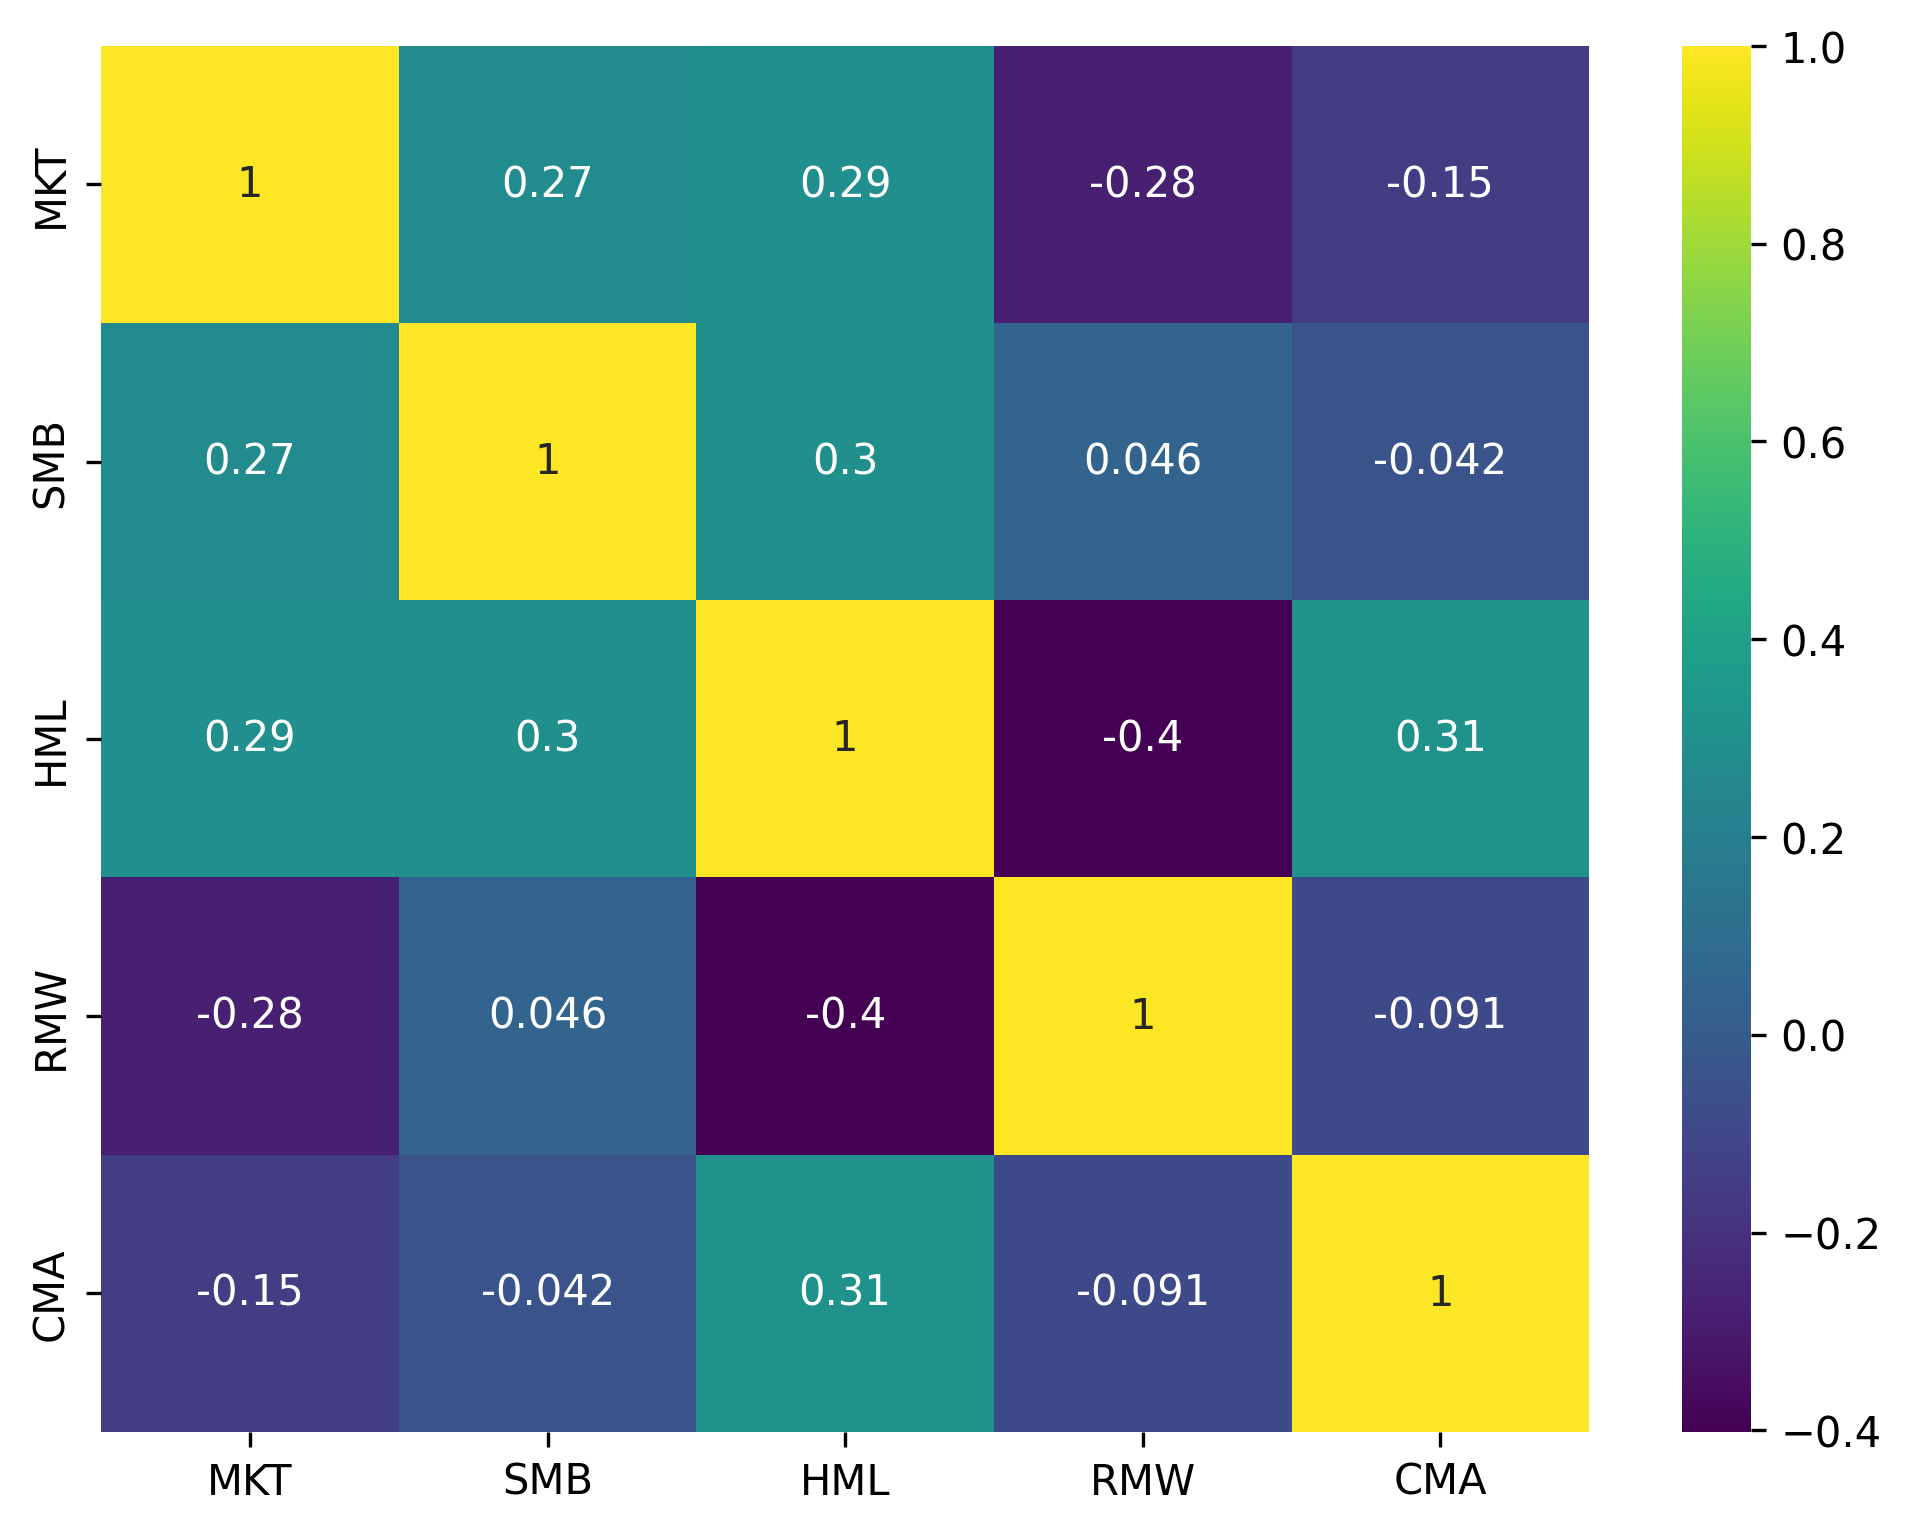

In [7]:
# 1.3 correlation matrix of factors

plt.figure(figsize=(8,6), dpi=300)
sns.heatmap(df_factors.drop('Rf', axis=1).corr(), annot=True, cmap='viridis')

In [8]:
np.round(df_factors.drop('Rf', axis=1).corr(), 2)

,MKT,SMB,HML,RMW,CMA
MKT,1.00,0.27,0.29,-0.28,-0.15
SMB,0.27,1.00,0.30,0.05,-0.04
HML,0.29,0.30,1.00,-0.40,0.31
RMW,-0.28,0.05,-0.40,1.00,-0.09
CMA,-0.15,-0.04,0.31,-0.09,1.00


- **Size and value are high-beta in India:** MKT is positively correlated with SMB (0.27) and HML (0.29), because Nifty 500 small/midcaps and value stocks (PSUs, banks, metals, energy) amplify market moves, unlike the US where HML is defensive.
- **Indian value stocks are low-profitability firms:** HML–RMW (−0.40) is the strongest correlation; cheap stocks have often been cheap because of weak profitability, so RMW may absorb part of the value premium.
- **HML is likely not redundant in India:** HML–CMA is only 0.31 versus about 0.7 in the US (FF 2015), as many value firms invested heavily in the post-2021 capex cycle; the spanning regression will test this formally.
- **SMB is a mid-vs-large-cap premium:** SMB is nearly uncorrelated with RMW and CMA because Nifty 500 excludes micro-caps, so even "small" stocks are established, profitable firms.
- **Caveat:** with 120 months, correlations above |0.18| are significant, but the sample is one decade dominated by the 2021–24 small/mid/PSU rally; sub-period checks are planned in Phase 4.

In [9]:
# 1.4 Spanning regressions

# Regress each factor on the other four factors.
# Intercept = part of the factor's average return that the
# other four factors cannot explain.

spanning_rows = []      # one row of results per factor
spanning_models = {}    # keep the fitted models to print full summaries later

for factor in FACTOR_COLS:

    # Left-hand side: the factor being tested
    y = df_factors[factor]

    # Right-hand side: the other four factors + a constant (the intercept)
    other_factors = [f for f in FACTOR_COLS if f != factor]
    X = sm.add_constant(df_factors[other_factors])

    # Plain OLS t-stats (what FF report)
    model_ols = sm.OLS(y, X).fit()

    # Same regression with Newey-West t-stats (robustness check)
    model_nw = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})

    spanning_models[factor] = model_ols

    # Collect the results for this factor
    row = {
        "dependent_factor": factor,
        "factor_mean_monthly_%": y.mean() * 100,
        "intercept_monthly_%": model_ols.params["const"] * 100,
        "t_intercept_ols": model_ols.tvalues["const"],
        "t_intercept_nw": model_nw.tvalues["const"],
        "p_intercept_ols": model_ols.pvalues["const"],
        "r_squared": model_ols.rsquared,
        "n_months": int(model_ols.nobs),
    }

    # Slope and t-stat on each of the other four factors
    for f in other_factors:
        row[f"slope_{f}"] = model_ols.params[f]
        row[f"t_{f}"] = model_ols.tvalues[f]

    spanning_rows.append(row)

spanning_df = pd.DataFrame(spanning_rows).set_index("dependent_factor")


In [10]:
# Simple verdict using the FF rule of thumb |t| > 2
spanning_df["verdict"] = np.where(
    spanning_df["t_intercept_ols"].abs() > 2,
    "adds information",
    "not significant (possibly redundant)",
)

# Show the key columns first
key_cols = [
    "factor_mean_monthly_%", "intercept_monthly_%",
    "t_intercept_ols", "t_intercept_nw", "r_squared", "verdict",
]
print("=== Spanning regressions: intercepts ===")
display(spanning_df[key_cols].round(3))

# Show the slopes (blank where the factor is the dependent variable)
slope_cols = [f"slope_{f}" for f in FACTOR_COLS] + [f"t_{f}" for f in FACTOR_COLS]
print("=== Spanning regressions: slopes and t-stats ===")
display(spanning_df[slope_cols].round(2))

=== Spanning regressions: intercepts ===


,factor_mean_monthly_%,intercept_monthly_%,t_intercept_ols,t_intercept_nw,r_squared,verdict
dependent_factor,,,,,,
MKT,0.446,-0.198,-0.443,-0.393,0.216,not significant (possibly redundant)
SMB,1.298,1.047,3.447,4.319,0.180,adds information
HML,0.841,0.208,0.629,0.647,0.367,not significant (possibly redundant)
RMW,-0.237,-0.177,-0.613,-0.728,0.235,not significant (possibly redundant)
CMA,0.085,0.020,0.083,0.093,0.171,not significant (possibly redundant)


=== Spanning regressions: slopes and t-stats ===


,slope_MKT,slope_SMB,slope_HML,slope_RMW,slope_CMA,t_MKT,t_SMB,t_HML,t_RMW,t_CMA
dependent_factor,,,,,,,,,,
MKT,NaN,0.30,0.26,-0.34,-0.45,NaN,2.31,2.09,-2.44,-2.64
SMB,0.15,NaN,0.31,0.26,-0.13,2.31,NaN,3.58,2.58,-1.07
HML,0.14,0.33,NaN,-0.43,0.51,2.09,3.58,NaN,-4.29,4.20
RMW,-0.14,0.21,-0.32,NaN,0.02,-2.44,2.58,-4.29,NaN,0.13
CMA,-0.13,-0.07,0.26,0.01,NaN,-2.64,-1.07,4.20,0.13,NaN


In [11]:
# Full regression output for HML
# This is the key FF (2015) test: is HML redundant?

print(spanning_models["HML"].summary())

                            OLS Regression Results                            
Dep. Variable:                    HML   R-squared:                       0.367
Model:                            OLS   Adj. R-squared:                  0.345
Method:                 Least Squares   F-statistic:                     16.67
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           8.43e-11
Time:                        17:11:19   Log-Likelihood:                 238.89
No. Observations:                 120   AIC:                            -467.8
Df Residuals:                     115   BIC:                            -453.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0021      0.003      0.629      0.5

HML’s own premium is significant on its own. Once you control for the other four factors, though, only 0.21% per month is left unexplained, and that remainder is statistically indistinguishable from zero. By the FF test, HML is redundant in your Indian sample, as it was in the US.

HML is redundant in India as in the US, but for a different reason. In the US it is spanned by investment (CMA). In India it is spanned mostly by size (SMB), plus its tilt toward low-profitability firms.

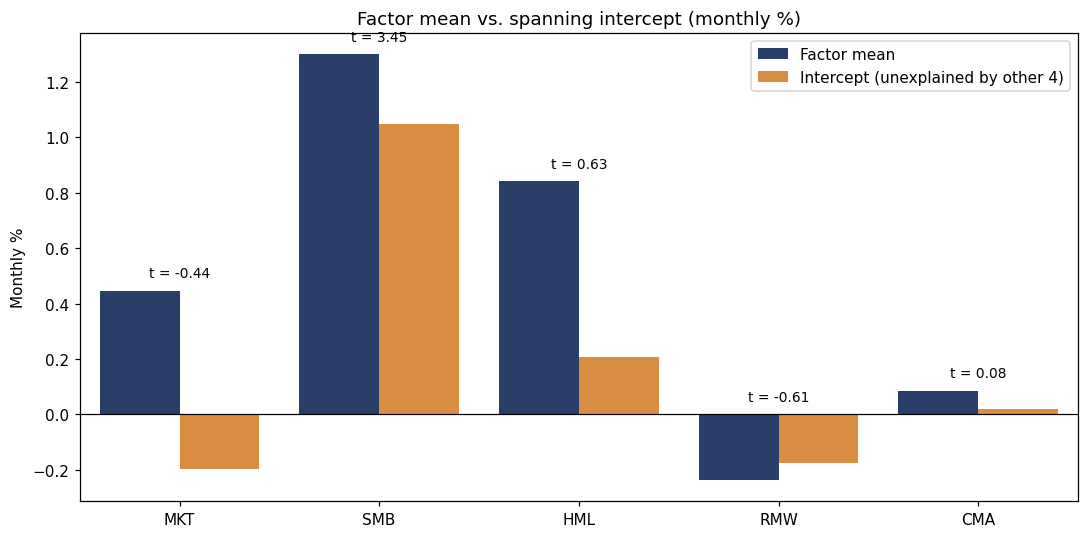

In [12]:
# Plot - factor mean vs spanning intercept

# Seaborn needs "long" format: one row per (factor, bar type)
plot_df = spanning_df[["factor_mean_monthly_%", "intercept_monthly_%"]].rename(
    columns={
        "factor_mean_monthly_%": "Factor mean",
        "intercept_monthly_%": "Intercept (unexplained by other 4)",
    }
)
plot_long = plot_df.reset_index().melt(
    id_vars="dependent_factor",
    var_name="Measure",
    value_name="Monthly %",
)

# Bar colours: navy for the factor mean, orange for the intercept
bar_colors = {
    "Factor mean": "#1f3b73",
    "Intercept (unexplained by other 4)": "#f28e2b",
}

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_long,
    x="dependent_factor",
    y="Monthly %",
    hue="Measure",
    palette=bar_colors,
    order=FACTOR_COLS,      # keep the order MKT, SMB, HML, RMW, CMA
    ax=ax,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Factor mean vs. spanning intercept (monthly %)")
ax.set_xlabel("")
ax.set_ylabel("Monthly %")
ax.legend(title="")

# Write the OLS t-stat of the intercept above each factor
for i, factor in enumerate(FACTOR_COLS):
    t = spanning_df.loc[factor, "t_intercept_ols"]
    top = max(plot_df.loc[factor].max(), 0)
    ax.text(i, top + 0.05, f"t = {t:.2f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_4_spanning_intercepts.png", bbox_inches="tight", dpi=300)
plt.show()

In [13]:
spanning_df.to_csv(OUTPUT_DIR / "phase_3_spanning_regressions.csv")
print("Saved:", OUTPUT_DIR / "phase_3_spanning_regressions.csv")

Saved: C:\Users\jayan\Study Materials\Fama-French_model\data\processed\phase_3_spanning_regressions.csv


In [14]:
FACTOR_COLORS = {
    "MKT": "#1f3b73",   # navy
    "SMB": "#f28e2b",   # orange
    "HML": "#2a9d8f",   # teal
    "RMW": "#e76f51",   # coral
    "CMA": "#8e6bbf",   # purple
}

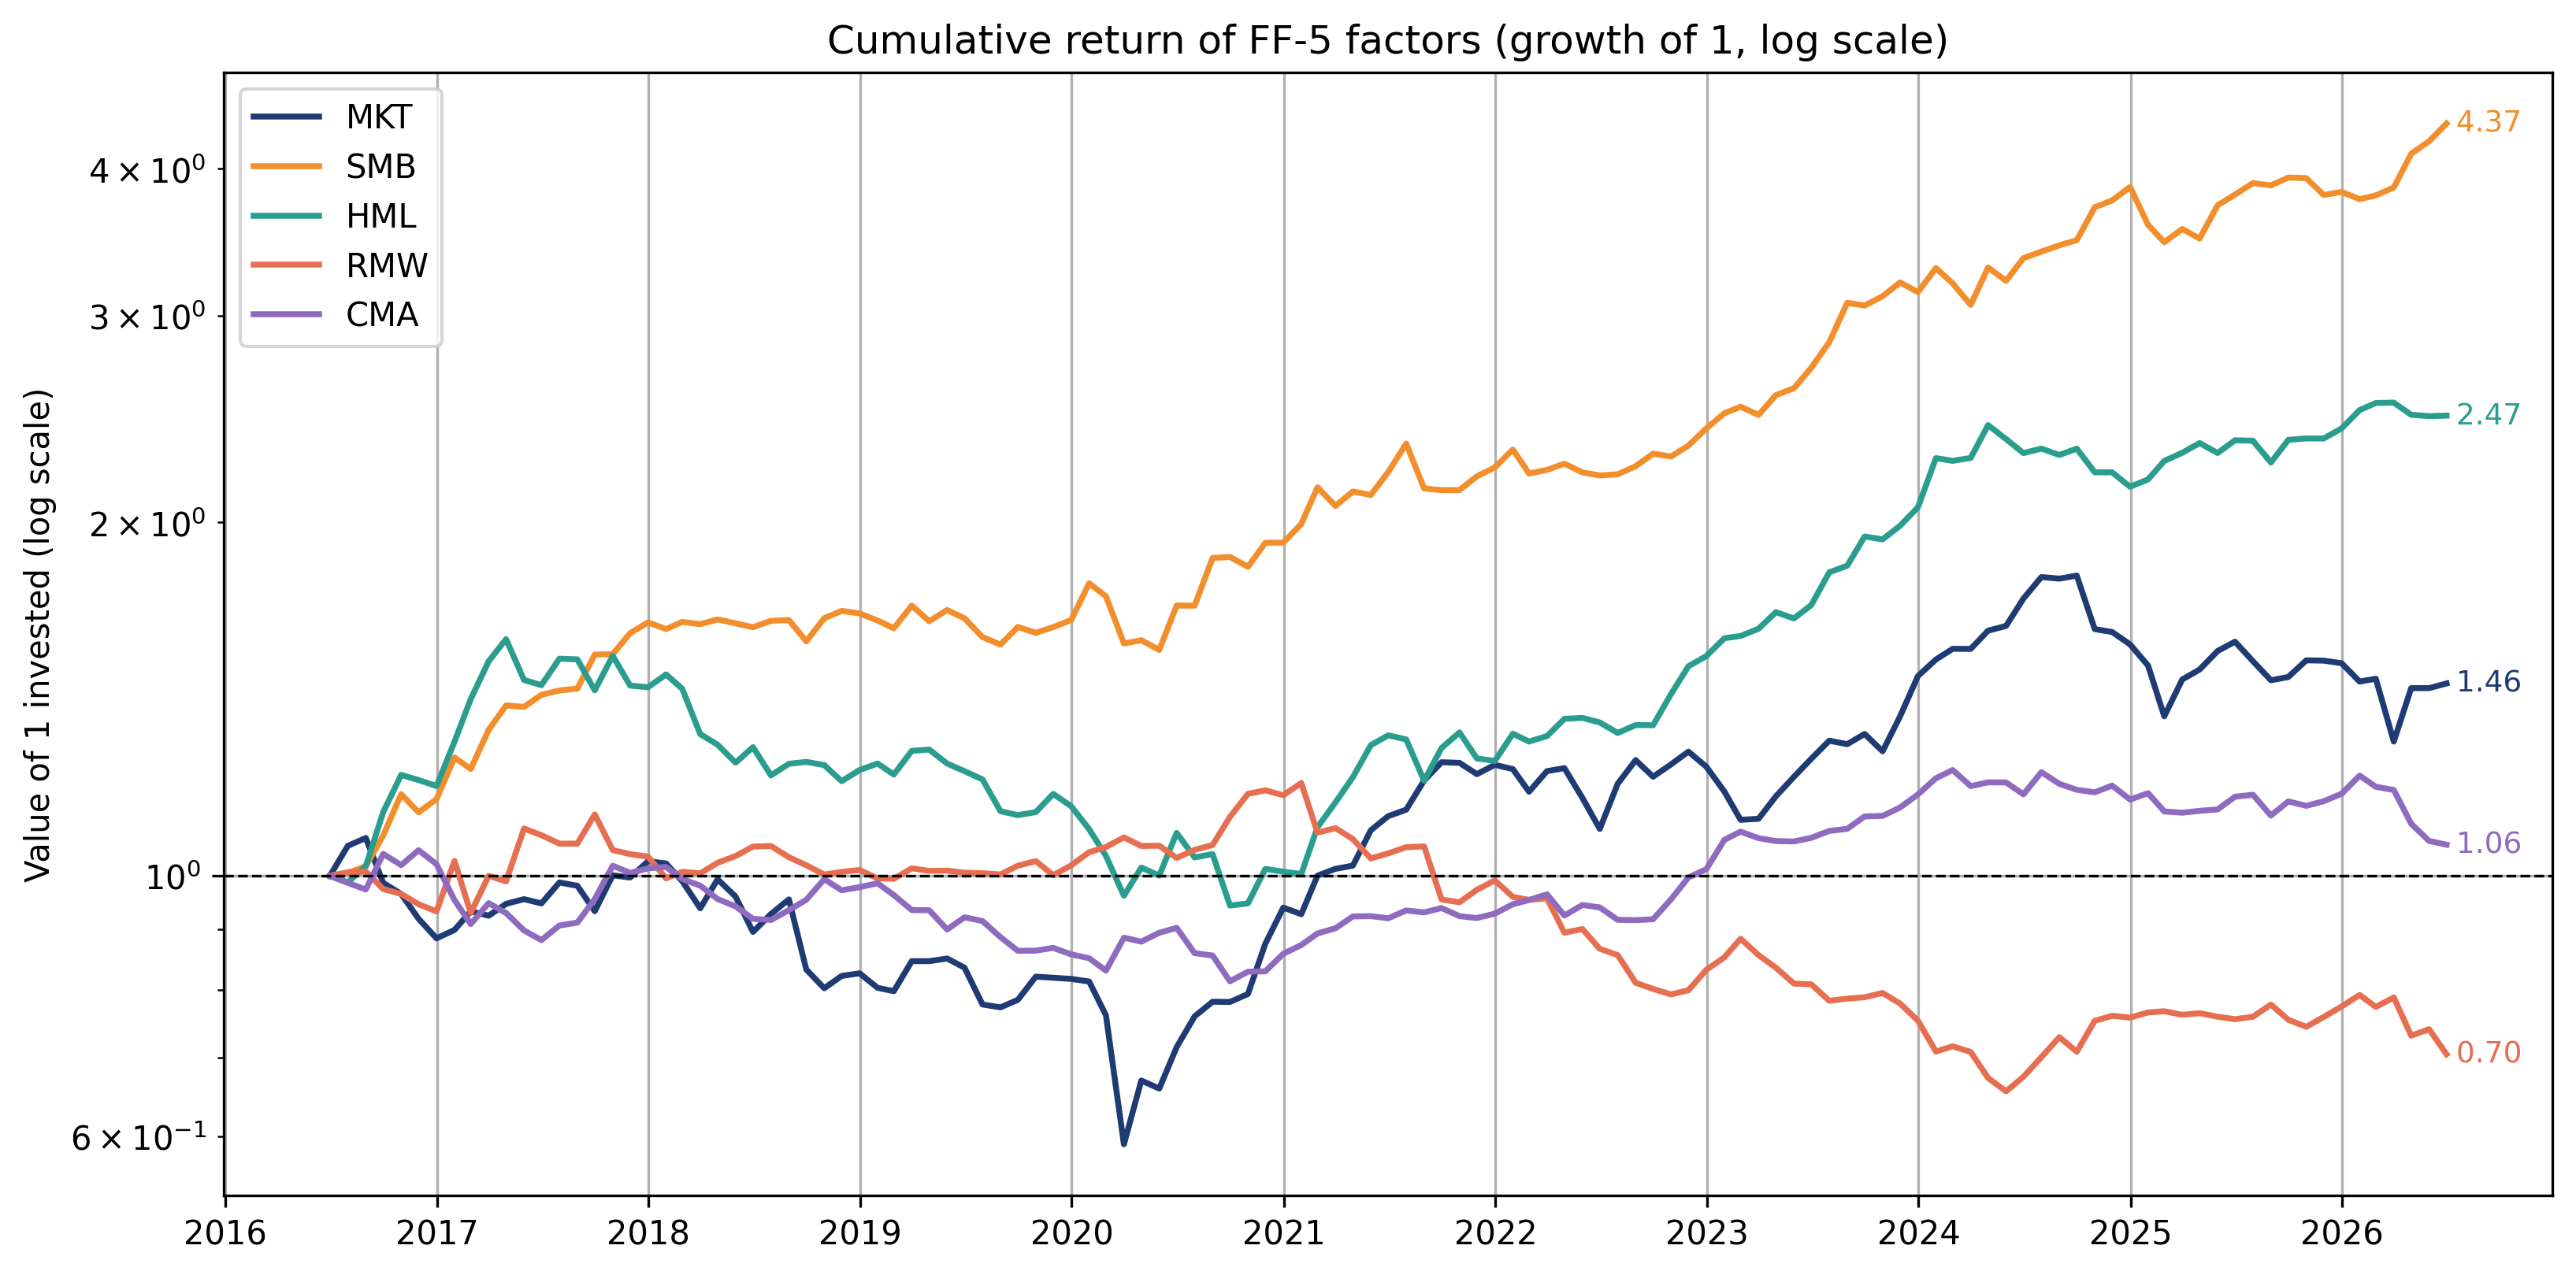

In [15]:
# 1.5 Cumulative return of each factor (log scale)
# Growth of Rs 1 invested in each factor from Jul-2016

# Growth of 1: multiply (1 + monthly return) month after month
cumulative = (1 + df_factors[FACTOR_COLS]).cumprod()

# Add a starting value of 1 at 30-Jun-2016 so every line starts at 1
start_date = df_factors.index.min() - pd.offsets.MonthEnd(1)
start_row = pd.DataFrame(1.0, index=[start_date], columns=FACTOR_COLS)
cumulative = pd.concat([start_row, cumulative])

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)

for factor in FACTOR_COLS:
    sns.lineplot(
        x=cumulative.index,
        y=cumulative[factor],
        label=factor,
        color=FACTOR_COLORS[factor],
        linewidth=1.8,
        ax=ax,
    )

ax.set_yscale("log")
ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Cumulative return of FF-5 factors (growth of 1, log scale)")
ax.set_xlabel("")
ax.set_ylabel("Value of 1 invested (log scale)")
ax.legend(title="")

# Show the ending value of each factor at the right edge of the chart
for factor in FACTOR_COLS:
    end_value = cumulative[factor].iloc[-1]
    ax.text(cumulative.index[-1], end_value, f" {end_value:.2f}",
            color=FACTOR_COLORS[factor], fontsize=9, va="center")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_5_cumulative_factors.png", bbox_inches="tight")
plt.grid()
plt.show()

**SMB = (average return of small portfolios) − (average return of big portfolios)** 

To earn it, you would buy ₹1 of small stocks and short ₹1 of big stocks at the same time. The 4.37 shows how much small stocks beat big stocks, not what a small-cap fund returned. A plain small-cap investor earned the market return plus this spread, and also took the market’s crashes.

**Inferences from cumulative return plot**

| Factor | Ending value | Approx. annual return | Pattern |
|:------:|:------------:|:---------------------:|:--------|
| SMB | 4.37 | ≈ 16% | Steady climb, almost all decade |
| HML | 2.47 | ≈ 9.5% | Down 2018–20, then strong 2021–24 |
| MKT | 1.46 | ≈ 3.9% | Covid crash, peak late 2024, then fell |
| CMA | 1.06 | ≈ 0.6% | Essentially no premium |
| RMW | 0.70 | ≈ −3.5% | Flat till 2021, fell 2022–24 |

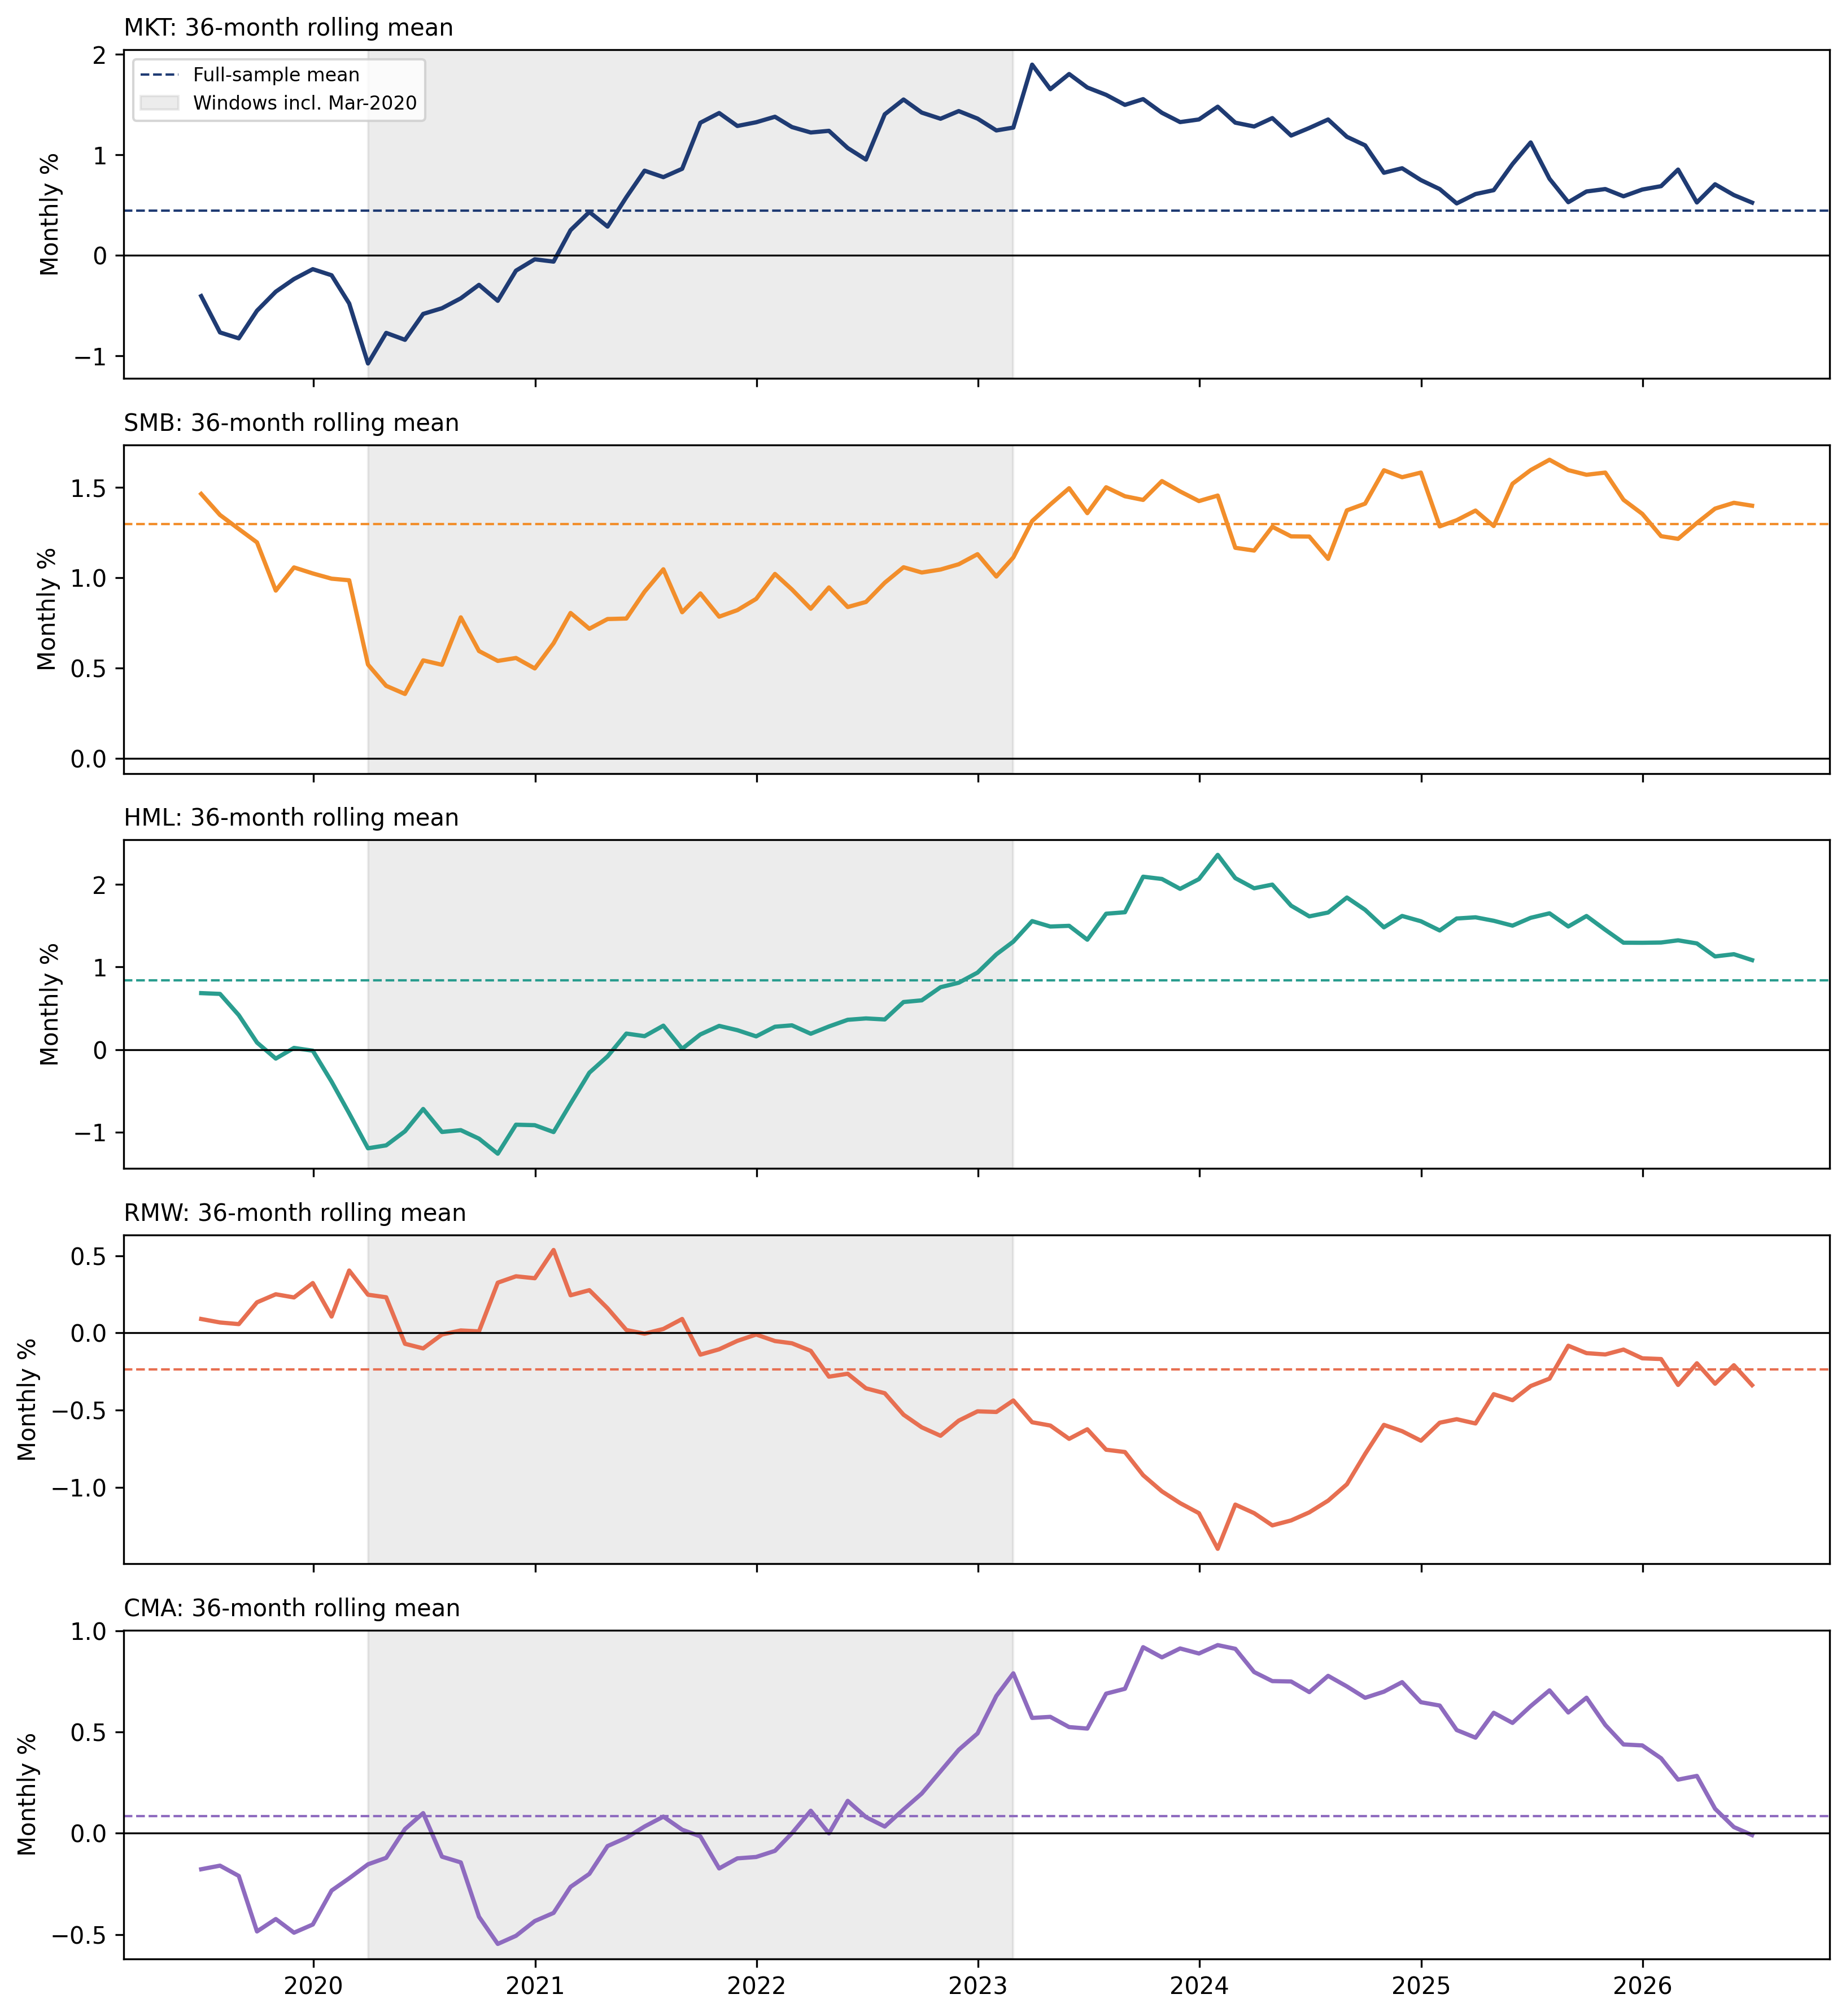

In [16]:
# 1.6 36-month rolling mean of each factor
# Is each premium stable, or does it come from one period?

ROLL_WINDOW = 36    # months

rolling_mean = df_factors[FACTOR_COLS].rolling(ROLL_WINDOW).mean() * 100   # monthly %
rolling_mean = rolling_mean.dropna()    # first 35 months have no full window

full_mean = df_factors[FACTOR_COLS].mean() * 100   # full-sample mean, for reference

# One small panel per factor, sharing the same x-axis
fig, axes = plt.subplots(len(FACTOR_COLS), 1, figsize=(11, 12), sharex=True, dpi=300)

for ax, factor in zip(axes, FACTOR_COLS):

    sns.lineplot(
        x=rolling_mean.index,
        y=rolling_mean[factor],
        color=FACTOR_COLORS[factor],
        linewidth=1.8,
        ax=ax,
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axhline(full_mean[factor], color=FACTOR_COLORS[factor],
               linewidth=1, linestyle="--", label="Full-sample mean")

    # Shade the 36 months whose windows contain the Covid crash (Mar-2020)
    ax.axvspan(pd.Timestamp("2020-03-31"), pd.Timestamp("2023-02-28"),
               color="grey", alpha=0.15, label="Windows incl. Mar-2020")

    ax.set_title(f"{factor}: 36-month rolling mean", fontsize=10, loc="left")
    ax.set_ylabel("Monthly %")
    ax.set_xlabel("")

axes[0].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_6_rolling_mean_factors.png", bbox_inches="tight")
plt.show()

***Interpretation***

First point appears in 2019 once first 36 months get over.

If a factor’s line rises or falls sharply while entering and leaving the grey band, its premium depends heavily on the Covid crash and recovery.

In [17]:
# ==========================================================
# STEP 2: Build Test Portfolios
# ==========================================================

In [18]:
# 2.0 Settings for test portfolios (same rules as Phase 2)

# Cleaned Phase 2 outputs (split-corrected returns, all filters applied)
CLEAN_PANEL_FILE = PROCESSED_DIR / "phase_2_monthly_panel_clean.csv"
FORMATION_FILE = PROCESSED_DIR / "phase_2_formation.csv"

# Characteristic column used by each sort (names in phase_2_formation.csv)
SORTS = {
    "BM":  "bm",    # Size x Book-to-Market
    "OP":  "op",    # Size x Operating profitability (financials already NaN)
    "INV": "inv",   # Size x Investment
}

# Formation years with a full joint FF5 sample (Phase 2 Steps 4.2b, 4.2c)
FIRST_FORMATION = "2016-06-30"
LAST_FORMATION = "2025-06-30"

# Labels for tables and plots (3x3 grid)
SIZE_LABELS = {1: "Small", 2: "Mid", 3: "Big"}
CHAR_LABELS = {1: "Low", 2: "Mid", 3: "High"}

In [19]:
# 2.1 Load Phase 2 cleaned panel and formation snapshot

panel_df = pd.read_csv(CLEAN_PANEL_FILE, parse_dates=["date", "formation_date"])
formation_df = pd.read_csv(FORMATION_FILE, parse_dates=["formation_date"])

# Keep only the months covered by the Phase 2 factors
panel_df = panel_df[panel_df["date"].isin(df_factors.index)]

# Keep only the formation years used for the joint FF5 sample
formation_df = formation_df[
    formation_df["formation_date"].between(FIRST_FORMATION, LAST_FORMATION)
]

print("Panel months:", panel_df["date"].nunique())   # expect 120
print("Formation years:", formation_df["formation_date"].dt.year.unique())

Panel months: 120
Formation years: [2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]


In [20]:
# 2.2 Eligible stocks per sort (same as Phase 2 Step 4.2)

def stocks_for_sort(sort_type):
    df = formation_df.copy()
    if sort_type == "BM":
        df = df[(df["book_value"] > 0) & (df["bm"] > 0)]
    elif sort_type == "OP":
        df = df[(df["book_value"] > 0) & df["op"].notna()]   # financials already NaN
    elif sort_type == "INV":
        df = df[df["inv"].notna()]                           # no BE filter (as Phase 2)
    return df


for sort_type in SORTS:
    counts = stocks_for_sort(sort_type).groupby("formation_date").size()
    print(sort_type, "eligible per year:", counts.min(), "to", counts.max())

BM eligible per year: 285 to 459
OP eligible per year: 237 to 372
INV eligible per year: 276 to 462


In [21]:
# 2.2a: Breakpoints (same convention as Phase 2)
# Size: all stocks with valid June ME; characteristic: Big stocks only

def cuts_for(values, n_groups):
    """3 groups: 30/70 (as Phase 2); 4-5 groups: equal quantiles (as FF)"""
    if n_groups == 3:
        qs = [BP_LOW, BP_HIGH]
    else:
        qs = [i / n_groups for i in range(1, n_groups)]
    return values.quantile(qs).values


def make_groups(df, char_col, n_groups):
    """Add size_group and char_group (1 = lowest) for each June"""
    out = []
    for fdate, year in df.groupby("formation_date"):
        all_stocks = formation_df[formation_df["formation_date"] == fdate]
        big_stocks = year[year["SIZE"] == "B"]               # Phase 2 median split

        size_cuts = cuts_for(all_stocks["me_june"], n_groups)
        char_cuts = cuts_for(big_stocks[char_col], n_groups)

        year = year.copy()
        year["size_group"] = np.searchsorted(size_cuts, year["me_june"], side="left") + 1
        year["char_group"] = np.searchsorted(char_cuts, year[char_col], side="left") + 1
        out.append(year)
    return pd.concat(out)

In [22]:
# 2.2b Choose the grid size (3x3, 4x4 or 5x5)
# Uses stock counts and weights only - never returns

def effective_n(weights):
    """1 / sum of squared weights: how many equal-weight stocks the cell behaves like"""
    w = weights / weights.sum()
    return 1 / (w ** 2).sum()


diag_rows = []

for n_groups in [3, 4, 5]:
    for sort_type, char_col in SORTS.items():

        df = make_groups(stocks_for_sort(sort_type), char_col, n_groups)
        n_years = df["formation_date"].nunique()

        cells = df.groupby(["formation_date", "size_group", "char_group"])
        n_stocks = cells["symbol"].count()
        eff_n = cells["me_june"].apply(effective_n)

        # Cells with no stocks at all do not appear in the groupby
        n_cells_expected = n_groups * n_groups * n_years
        empty_cells = n_cells_expected - len(n_stocks)

        diag_rows.append({
            "grid": f"{n_groups}x{n_groups}",
            "sort_type": sort_type,
            "min_stocks": 0 if empty_cells > 0 else n_stocks.min(),
            "avg_stocks": n_stocks.mean(),
            "cells_below_min": (n_stocks < MIN_STOCKS).sum() + empty_cells,
            "min_effective_n": 0 if empty_cells > 0 else eff_n.min(),
            "cells_eff_n_below_min": (eff_n < MIN_STOCKS).sum() + empty_cells,
            "total_cells": n_cells_expected,
        })

grid_diag = pd.DataFrame(diag_rows)

# A grid passes only if no cell fails either test, in any year
grid_diag["passes"] = (
    (grid_diag["cells_below_min"] == 0) & (grid_diag["cells_eff_n_below_min"] == 0)
)

display(grid_diag.round(1))

# Largest grid that passes for ALL three sorts
passing = grid_diag.groupby("grid")["passes"].all()
print(passing)

,grid,sort_type,min_stocks,avg_stocks,cells_below_min,min_effective_n,cells_eff_n_below_min,total_cells,passes
0,3x3,BM,1,40.8,2,1.0,5,90,False
1,3x3,OP,10,33.4,0,4.0,1,90,False
2,3x3,INV,18,41.2,0,7.3,0,90,True
3,4x4,BM,0,23.1,7,0.0,11,160,False
4,4x4,OP,4,18.8,3,3.0,12,160,False
5,4x4,INV,9,23.2,0,6.0,0,160,True
6,5x5,BM,0,14.7,19,0.0,29,250,False
7,5x5,OP,1,12.0,14,1.0,32,250,False
8,5x5,INV,5,14.8,0,4.0,8,250,False


grid
3x3    False
4x4    False
5x5    False
Name: passes, dtype: bool


In [23]:
# 2.2c: Which 3x3 cells fail, and in which years?

fail_rows = []

for sort_type, char_col in SORTS.items():

    df = make_groups(stocks_for_sort(sort_type), char_col, 3)
    cells = df.groupby(["formation_date", "size_group", "char_group"])

    cell_check = pd.DataFrame({
        "n_stocks": cells["symbol"].count(),
        "effective_n": cells["me_june"].apply(effective_n),
        "top_stock": cells.apply(lambda g: g.loc[g["me_june"].idxmax(), "symbol"]),
    }).reset_index()

    cell_check["sort_type"] = sort_type
    fail_rows.append(
        cell_check[(cell_check["n_stocks"] < MIN_STOCKS) |
                   (cell_check["effective_n"] < MIN_STOCKS)]
    )

failing_cells = pd.concat(fail_rows, ignore_index=True)
failing_cells["size"] = failing_cells["size_group"].map(SIZE_LABELS)
failing_cells["char"] = failing_cells["char_group"].map(CHAR_LABELS)

display(failing_cells[["sort_type", "formation_date", "size", "char",
                       "n_stocks", "effective_n", "top_stock"]].round(1))

,sort_type,formation_date,size,char,n_stocks,effective_n,top_stock
0,BM,2016-06-30,Small,Low,5,4.5,TRITURBINE
1,BM,2019-06-30,Small,Low,5,4.1,IEX
2,BM,2020-06-30,Small,Low,1,1.0,AFFLE
3,BM,2021-06-30,Small,Low,3,2.7,MMTC
4,BM,2022-06-30,Small,Low,6,5.0,ACUTAAS
5,OP,2020-06-30,Big,Low,24,4.0,RELIANCE


## What is the 3×3 grid?

Every June, each eligible stock is placed in **one cell of a 3×3 grid**, based on two
characteristics measured at that June. Each cell is a **test portfolio**.

- **Rows = Size** (June market cap): Small, Mid, Big
- **Columns = one characteristic**: B/M, OP or Investment (one grid per characteristic)

### Example: Size × B/M grid

| | **Low B/M** (growth) | **Mid B/M** | **High B/M** (value) |
|---|---|---|---|
| **Small** | `BM_S1_C1` | `BM_S1_C2` | `BM_S1_C3` |
| **Mid** | `BM_S2_C1` | `BM_S2_C2` | `BM_S2_C3` |
| **Big** | `BM_S3_C1` | `BM_S3_C2` | `BM_S3_C3` |

`BM_S1_C3`, for example, holds the small value stocks: small market cap, high book-to-market.

### The three grids

| Grid | Columns: Low (C1) → High (C3) |
|---|---|
| Size × B/M | Growth → Value |
| Size × OP | Weak profitability → Robust profitability |
| Size × Investment | Conservative (low asset growth) → Aggressive (high asset growth) |

3 grids × 9 cells = **27 test portfolios**.

### How a stock is placed

- **Size breakpoints:** 30th and 70th percentiles of June market cap across all eligible stocks.
- **Characteristic breakpoints:** 30th and 70th percentiles among **Big stocks only**, applied
  to all stocks (the same convention as the Phase 2 factors, the Indian analog of FF's NYSE breakpoints).
- **Independent sorts:** size and the characteristic are sorted separately, and a stock's cell is
  where its two groups meet. So cells can hold different numbers of stocks.

### What happens inside each cell

- Stocks stay in their cell from **July of year t to June of year t+1**, then the grid is rebuilt.
- Each month, the cell's return is the **value-weighted** average of its stocks' returns,
  weighted by market cap at the end of the previous month.
- Subtracting the T-bill rate gives the cell's **excess return**, which the FF-5 factors must explain.

### Why the grid matters

If FF-5 is correct, the factors should explain the **average return of every cell**. Cells
with very different average returns (for example, small value vs big growth) give the model a
demanding test. Any cell the model cannot explain shows up as a non-zero intercept in Step 3.

### Grid choice (decided before looking at any portfolio returns)

- 4×4 and 5×5 grids produce empty cells in the BM and OP sorts, so they cannot be used.
- 3×3 is used for all three sorts: no cell is ever empty, and 6 of 270 cell-years (≈2%)
  have fewer than 5 stocks or an effective number of stocks below 5.
- **BM Small-Growth (`BM_S1_C1`) is thin in 5 of 10 years** (a single stock, AFFLE, in 2020).
  Cause: characteristic breakpoints come from Big stocks (Phase 2 convention), and few small
  stocks in Nifty 500 are as expensive as large-cap growth stocks. This portfolio is flagged
  in all results, and the BM GRS test is also reported without it.
- **OP Big-Weak in 2020** is dominated by Reliance (effective number 4.0), reflecting
  Indian market-cap concentration rather than a data issue.

In [24]:
# 2.3 Assign each stock to a 3x3 portfolio (each June)
# Independent sorts, Phase 2 breakpoint convention (Step 2.2a)

# Grid size: decided after the diagnostic in Step 2.2b (3, 4 or 5)
N_GROUPS = 3

# Portfolios found unreliable in Step 2.2c (thin in 5 of 10 years)
FLAGGED_PORTFOLIOS = ["BM_S1_C1"]

holdings_list = []

for sort_type, char_col in SORTS.items():

    df = make_groups(stocks_for_sort(sort_type), char_col, N_GROUPS)

    df["sort_type"] = sort_type
    df["char_value"] = df[char_col]
    df["portfolio_id"] = (
        sort_type + "_S" + df["size_group"].astype(str) + "_C" + df["char_group"].astype(str)
    )

    holdings_list.append(
        df[["formation_date", "symbol", "sort_type", "size_group",
            "char_group", "portfolio_id", "me_june", "char_value"]]
    )

holdings_df = pd.concat(holdings_list, ignore_index=True)

print("Holdings rows:", len(holdings_df))
print(holdings_df.groupby("sort_type")["portfolio_id"].nunique())   # expect 9 each

Holdings rows: 10387
sort_type
BM     9
INV    9
OP     9
Name: portfolio_id, dtype: int64


In [25]:
# 2.4 Monthly value-weighted portfolio returns
# Weight = market equity at end of previous month (me_lag)

# Attach each stock-month to its portfolio(s) for that holding year
merged = panel_df.merge(
    holdings_df[["formation_date", "symbol", "sort_type",
                 "size_group", "char_group", "portfolio_id"]],
    on=["symbol", "formation_date"],
    how="inner",
)

# A stock-month needs both a return and a positive weight
merged = merged.dropna(subset=["ret", "me_lag"])
merged = merged[merged["me_lag"] > 0]

merged["weighted_ret"] = merged["ret"] * merged["me_lag"]

test_ports = (
    merged.groupby(["date", "sort_type", "size_group", "char_group", "portfolio_id"])
    .agg(
        weighted_ret_sum=("weighted_ret", "sum"),
        total_me=("me_lag", "sum"),
        n_stocks=("symbol", "count"),
    )
    .reset_index()
)

test_ports["ret"] = test_ports["weighted_ret_sum"] / test_ports["total_me"]

# Excess return = portfolio return - Rf (same Rf as the Phase 2 factors)
test_ports = test_ports.merge(
    df_factors[["Rf"]], left_on="date", right_index=True, how="left"
)
test_ports["excess_ret"] = test_ports["ret"] - test_ports["Rf"]

# Flag thin portfolio-months (kept, not set to NaN: GRS needs complete series)
test_ports["is_thin"] = test_ports["n_stocks"] < MIN_STOCKS

test_ports = test_ports[
    ["date", "sort_type", "size_group", "char_group", "portfolio_id",
     "ret", "excess_ret", "n_stocks", "total_me", "is_thin"]
].sort_values(["sort_type", "portfolio_id", "date"]).reset_index(drop=True)

test_ports.head()

,date,sort_type,size_group,char_group,portfolio_id,ret,excess_ret,n_stocks,total_me,is_thin
0,2016-07-31,BM,1,1,BM_S1_C1,0.075127,0.069459,5,14981.251360,False
1,2016-08-31,BM,1,1,BM_S1_C1,0.011268,0.005764,5,16106.751451,False
2,2016-09-30,BM,1,1,BM_S1_C1,-0.009181,-0.014651,5,16257.913344,False
3,2016-10-31,BM,1,1,BM_S1_C1,0.084864,0.079415,5,16105.439646,False
4,2016-11-30,BM,1,1,BM_S1_C1,-0.074775,-0.080080,5,17472.212562,False


In [26]:
# 2.5: Data checks

n_factor_months = len(df_factors)
months_per_port = test_ports.groupby("portfolio_id")["date"].nunique()

print("Portfolios:", test_ports["portfolio_id"].nunique(), "(expected 27)")
print("Portfolios with missing months:",
      (months_per_port < n_factor_months).sum())          # must be 0
print("Missing excess returns:", test_ports["excess_ret"].isna().sum())   # must be 0
print("Minimum stocks in any portfolio-month:", test_ports["n_stocks"].min())
print("Thin portfolio-months:", test_ports["is_thin"].sum())

# Which portfolios have thin months?
print(test_ports[test_ports["is_thin"]].groupby("portfolio_id").size())

Portfolios: 27 (expected 27)
Portfolios with missing months: 0
Missing excess returns: 0
Minimum stocks in any portfolio-month: 1
Thin portfolio-months: 24
portfolio_id
BM_S1_C1    24
dtype: int64


In [27]:
# 2.6: Summary of each portfolio (FF Table 1 style)

port_summary = test_ports.groupby("portfolio_id").agg(
    sort_type=("sort_type", "first"),
    size_group=("size_group", "first"),
    char_group=("char_group", "first"),
    mean_excess=("excess_ret", "mean"),
    std_excess=("excess_ret", "std"),
    n_months=("excess_ret", "count"),
    avg_n_stocks=("n_stocks", "mean"),
    min_n_stocks=("n_stocks", "min"),
    thin_months=("is_thin", "sum"),
)

port_summary["t_stat"] = port_summary["mean_excess"] / (
    port_summary["std_excess"] / np.sqrt(port_summary["n_months"])
)
port_summary["mean_excess_monthly_%"] = port_summary["mean_excess"] * 100
port_summary["std_monthly_%"] = port_summary["std_excess"] * 100
port_summary["flagged"] = port_summary.index.isin(FLAGGED_PORTFOLIOS)

port_summary = port_summary[
    ["sort_type", "size_group", "char_group", "mean_excess_monthly_%",
     "std_monthly_%", "t_stat", "avg_n_stocks", "min_n_stocks",
     "thin_months", "n_months", "flagged"]
]

port_summary.round(2)

,sort_type,size_group,char_group,mean_excess_monthly_%,std_monthly_%,t_stat,avg_n_stocks,min_n_stocks,thin_months,n_months,flagged
portfolio_id,,,,,,,,,,,
BM_S1_C1,BM,1,1,2.56,11.36,2.47,9.34,1,24,120,True
BM_S1_C2,BM,1,2,2.53,7.52,3.69,36.83,19,0,120,False
BM_S1_C3,BM,1,3,2.45,8.06,3.33,60.33,42,0,120,False
BM_S2_C1,BM,2,1,0.80,5.70,1.54,34.37,24,0,120,False
BM_S2_C2,BM,2,2,1.23,5.89,2.29,61.63,48,0,120,False
BM_S2_C3,BM,2,3,1.26,7.76,1.78,48.84,34,0,120,False
BM_S3_C1,BM,3,1,-0.18,5.75,-0.34,33.62,26,0,120,False
BM_S3_C2,BM,3,2,0.31,5.09,0.68,44.42,26,0,120,False
BM_S3_C3,BM,3,3,0.72,6.53,1.21,30.82,21,0,120,False


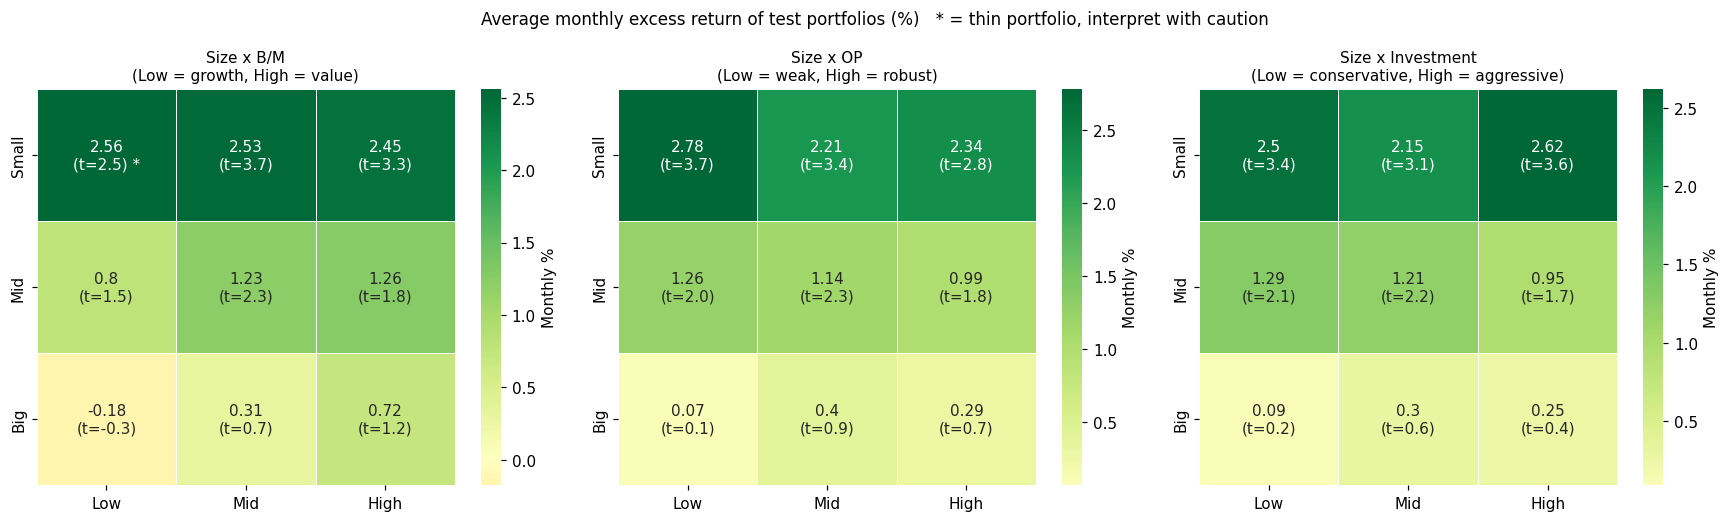

In [28]:
# 2.7 Plot - heatmap of average excess return per sort
# Rows = size, columns = characteristic (FF Table 1, visually)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

titles = {
    "BM":  "Size x B/M\n(Low = growth, High = value)",
    "OP":  "Size x OP\n(Low = weak, High = robust)",
    "INV": "Size x Investment\n(Low = conservative, High = aggressive)",
}

for ax, sort_type in zip(axes, SORTS.keys()):

    s = port_summary[port_summary["sort_type"] == sort_type].reset_index()

    means = s.pivot(index="size_group", columns="char_group", values="mean_excess_monthly_%")
    tstats = s.pivot(index="size_group", columns="char_group", values="t_stat")
    ids = s.pivot(index="size_group", columns="char_group", values="portfolio_id")

    # Cell text: mean, t-stat below it, * for flagged portfolios
    annot = means.round(2).astype(str) + "\n(t=" + tstats.round(1).astype(str) + ")"
    annot = annot.where(~ids.isin(FLAGGED_PORTFOLIOS), annot + " *")

    means.index = [SIZE_LABELS[i] for i in means.index]
    means.columns = [CHAR_LABELS[c] for c in means.columns]

    sns.heatmap(means, annot=annot.values, fmt="", cmap="RdYlGn", center=0,
                linewidths=0.5, cbar_kws={"label": "Monthly %"}, ax=ax)

    ax.set_title(titles[sort_type], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Average monthly excess return of test portfolios (%)   "
             "* = thin portfolio, interpret with caution", fontsize=11)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_7_test_portfolio_heatmaps.png", bbox_inches="tight", dpi=300)
plt.show()

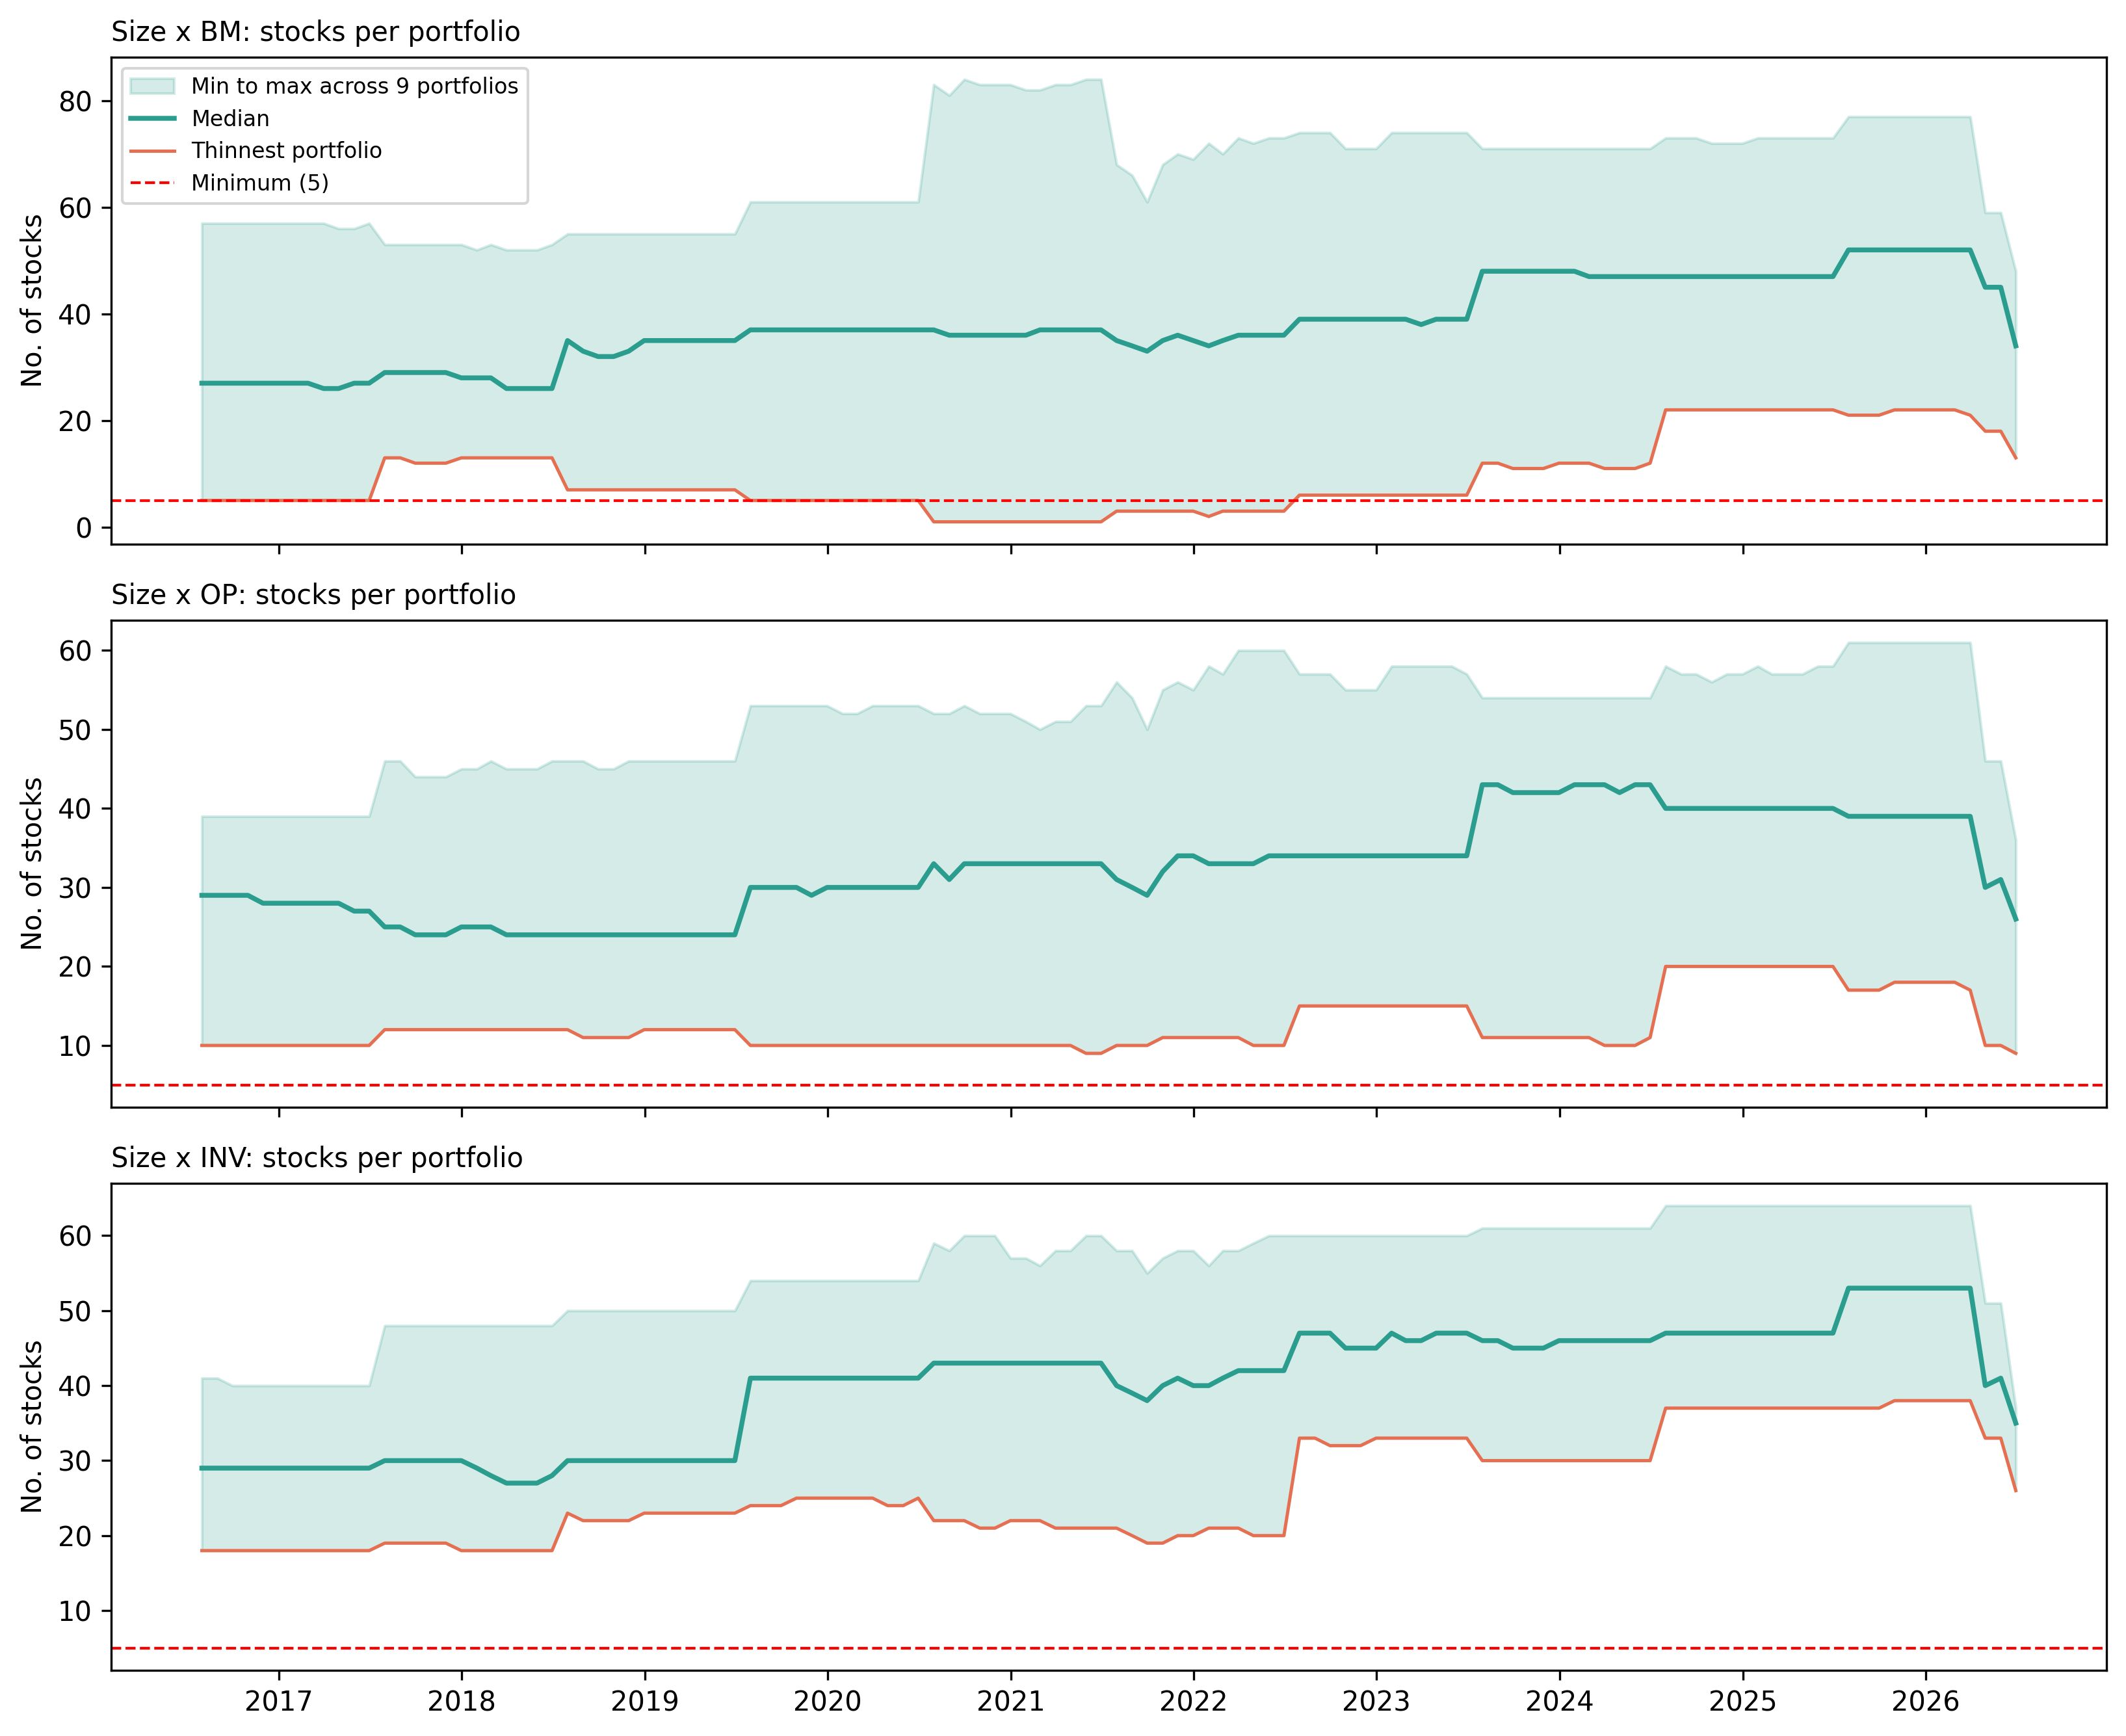

In [29]:
# 2.8 Plot - number of stocks per portfolio over time
# Min / median / max across the 9 portfolios of each sort

n_stats = (
    test_ports.groupby(["date", "sort_type"])["n_stocks"]
    .agg(["min", "median", "max"])
    .reset_index()
)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), dpi=300, sharex=True)

for ax, sort_type in zip(axes, SORTS.keys()):

    s = n_stats[n_stats["sort_type"] == sort_type]

    ax.fill_between(s["date"], s["min"], s["max"], color="#2a9d8f", alpha=0.2,
                    label="Min to max across 9 portfolios")
    sns.lineplot(x=s["date"], y=s["median"], color="#2a9d8f", linewidth=1.8,
                 label="Median", ax=ax)
    sns.lineplot(x=s["date"], y=s["min"], color="#e76f51", linewidth=1.2,
                 label="Thinnest portfolio", ax=ax)
    ax.axhline(MIN_STOCKS, color="red", linestyle="--", linewidth=1,
               label=f"Minimum ({MIN_STOCKS})")

    ax.set_title(f"Size x {sort_type}: stocks per portfolio", fontsize=10, loc="left")
    ax.set_ylabel("No. of stocks")
    ax.set_xlabel("")

axes[0].legend(loc="upper left", fontsize=8)
for ax in axes[1:]:
    ax.get_legend().remove()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_8_stocks_per_portfolio.png", bbox_inches="tight", dpi=300)
plt.show()

In [30]:
# 2.9 Save files for Steps 3-4 and Phases 4-5

test_ports.to_csv(OUTPUT_DIR / "phase_3_test_portfolios.csv", index=False)
holdings_df.to_csv(OUTPUT_DIR / "phase_3_portfolio_holdings.csv", index=False)
port_summary.to_csv(OUTPUT_DIR / "phase_3_portfolio_summary.csv")

print("Saved:")
print(" - phase_3_test_portfolios.csv")
print(" - phase_3_portfolio_holdings.csv")
print(" - phase_3_portfolio_summary.csv")

Saved:
 - phase_3_test_portfolios.csv
 - phase_3_portfolio_holdings.csv
 - phase_3_portfolio_summary.csv


In [31]:
# ==========================================================
# STEP 3: Time-series Regressions
# ==========================================================

In [32]:
# 3.0 Load test portfolios and line them up with the factors

test_ports_df = pd.read_csv(OUTPUT_DIR / "phase_3_test_portfolios.csv", parse_dates=["date"])

# Wide table: one column of excess returns per portfolio (date x 27)
excess_wide = test_ports_df.pivot(index="date", columns="portfolio_id", values="excess_ret")
excess_wide = excess_wide.sort_index()

PORTFOLIO_IDS = list(excess_wide.columns)

# Join the factors on date: every regression uses exactly the same 120 months
reg_data = excess_wide.join(df_factors[FACTOR_COLS], how="inner")

# Sort / size / characteristic group of each portfolio (for tables and plots)
port_info = (
    test_ports_df[["portfolio_id", "sort_type", "size_group", "char_group"]]
    .drop_duplicates()
    .set_index("portfolio_id")
)

print("Portfolios:", len(PORTFOLIO_IDS))                         # expect 27
print("Months:", len(reg_data), "| factor months:", len(df_factors))   # must be equal
print("Missing values:", reg_data.isna().sum().sum())            # must be 0

Portfolios: 27
Months: 120 | factor months: 120
Missing values: 0


In [33]:
# 3.1 Time-series regressions, Newey-West standard errors
# R_p - Rf = a + loadings x factors + e, for every portfolio and model

result_rows = []
residual_list = []

for pid in PORTFOLIO_IDS:

    y = reg_data[pid]    # portfolio excess return

    for model_name, model_factors in MODELS.items():

        X = sm.add_constant(reg_data[model_factors])

        # Newey-West (HAC) standard errors for all t-stats
        fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})

        row = {
            "portfolio_id": pid,
            "model": model_name,
            "a_monthly_%": fit.params["const"] * 100,      # intercept
            "t_a": fit.tvalues["const"],                    # Newey-West t-stat
            "p_a": fit.pvalues["const"],
            "r_squared": fit.rsquared,
            "adj_r_squared": fit.rsquared_adj,
            "resid_std_monthly_%": np.sqrt(fit.mse_resid) * 100,
            "n_months": int(fit.nobs),
        }

        # Loading and Newey-West t-stat for each factor (blank if not in the model)
        for f in FACTOR_COLS:
            row[f"b_{f}"] = fit.params.get(f, np.nan)
            row[f"t_{f}"] = fit.tvalues.get(f, np.nan)

        result_rows.append(row)

        # Residuals, one row per month
        residual_list.append(pd.DataFrame({
            "date": fit.resid.index,
            "portfolio_id": pid,
            "model": model_name,
            "residual": fit.resid.values,
        }))

reg_results = pd.DataFrame(result_rows)
reg_results = reg_results.merge(port_info, left_on="portfolio_id", right_index=True)
reg_results["flagged"] = reg_results["portfolio_id"].isin(FLAGGED_PORTFOLIOS)

# Keep the models in the order CAPM, FF3, FF5 in all tables
reg_results["model"] = pd.Categorical(reg_results["model"], categories=list(MODELS), ordered=True)
reg_results = reg_results.sort_values(["sort_type", "portfolio_id", "model"]).reset_index(drop=True)

residuals_df = pd.concat(residual_list, ignore_index=True)

print("Regressions run:", len(reg_results))     # expect 27 x 3 = 81
reg_results[reg_results["model"] == "FF5"][
    ["portfolio_id", "a_monthly_%", "t_a", "b_MKT", "b_SMB", "b_HML",
     "b_RMW", "b_CMA", "r_squared", "flagged"]
].round(2)

Regressions run: 81


,portfolio_id,a_monthly_%,t_a,b_MKT,b_SMB,b_HML,b_RMW,b_CMA,r_squared,flagged
2,BM_S1_C1,0.34,0.52,0.96,1.34,0.04,-0.16,-0.25,0.49,True
5,BM_S1_C2,0.78,3.35,1.00,1.04,-0.15,-0.28,0.12,0.86,False
8,BM_S1_C3,0.42,2.23,1.08,1.00,0.26,-0.11,0.06,0.94,False
11,BM_S2_C1,-0.18,-0.75,0.93,0.58,-0.22,0.04,0.18,0.85,False
14,BM_S2_C2,0.08,0.61,0.92,0.58,-0.01,-0.06,-0.13,0.92,False
17,BM_S2_C3,-0.50,-2.54,1.08,0.66,0.45,-0.07,0.20,0.93,False
20,BM_S3_C1,0.24,1.35,1.08,-0.30,-0.66,-0.14,0.08,0.87,False
23,BM_S3_C2,-0.10,-0.59,0.94,-0.02,0.08,0.16,-0.10,0.89,False
26,BM_S3_C3,-0.04,-0.25,1.00,-0.16,0.60,-0.05,0.09,0.90,False
29,INV_S1_C1,0.54,2.19,1.08,1.04,0.05,-0.22,0.32,0.90,False


In [34]:
# 3.2 Model-level summary of the intercepts
# (the joint GRS test comes in Step 4)

reg_results["abs_a_%"] = reg_results["a_monthly_%"].abs()
reg_results["a_significant"] = reg_results["t_a"].abs() > 2    # FF rule of thumb, NW t-stat

intercept_summary = (
    reg_results.groupby(["sort_type", "model"], observed=True)
    .agg(
        avg_abs_a_pct=("abs_a_%", "mean"),
        n_significant_a=("a_significant", "sum"),
        n_portfolios=("portfolio_id", "count"),
        avg_r_squared=("r_squared", "mean"),
    )
    .reset_index()
)

intercept_summary.round(3)

,sort_type,model,avg_abs_a_pct,n_significant_a,n_portfolios,avg_r_squared
0,BM,CAPM,0.950,4,9,0.690
1,BM,FF3,0.313,3,9,0.842
2,BM,FF5,0.298,3,9,0.848
3,INV,CAPM,0.911,5,9,0.755
4,INV,FF3,0.241,2,9,0.871
5,INV,FF5,0.241,2,9,0.898
6,OP,CAPM,0.895,5,9,0.707
7,OP,FF3,0.301,1,9,0.819
8,OP,FF5,0.290,1,9,0.850


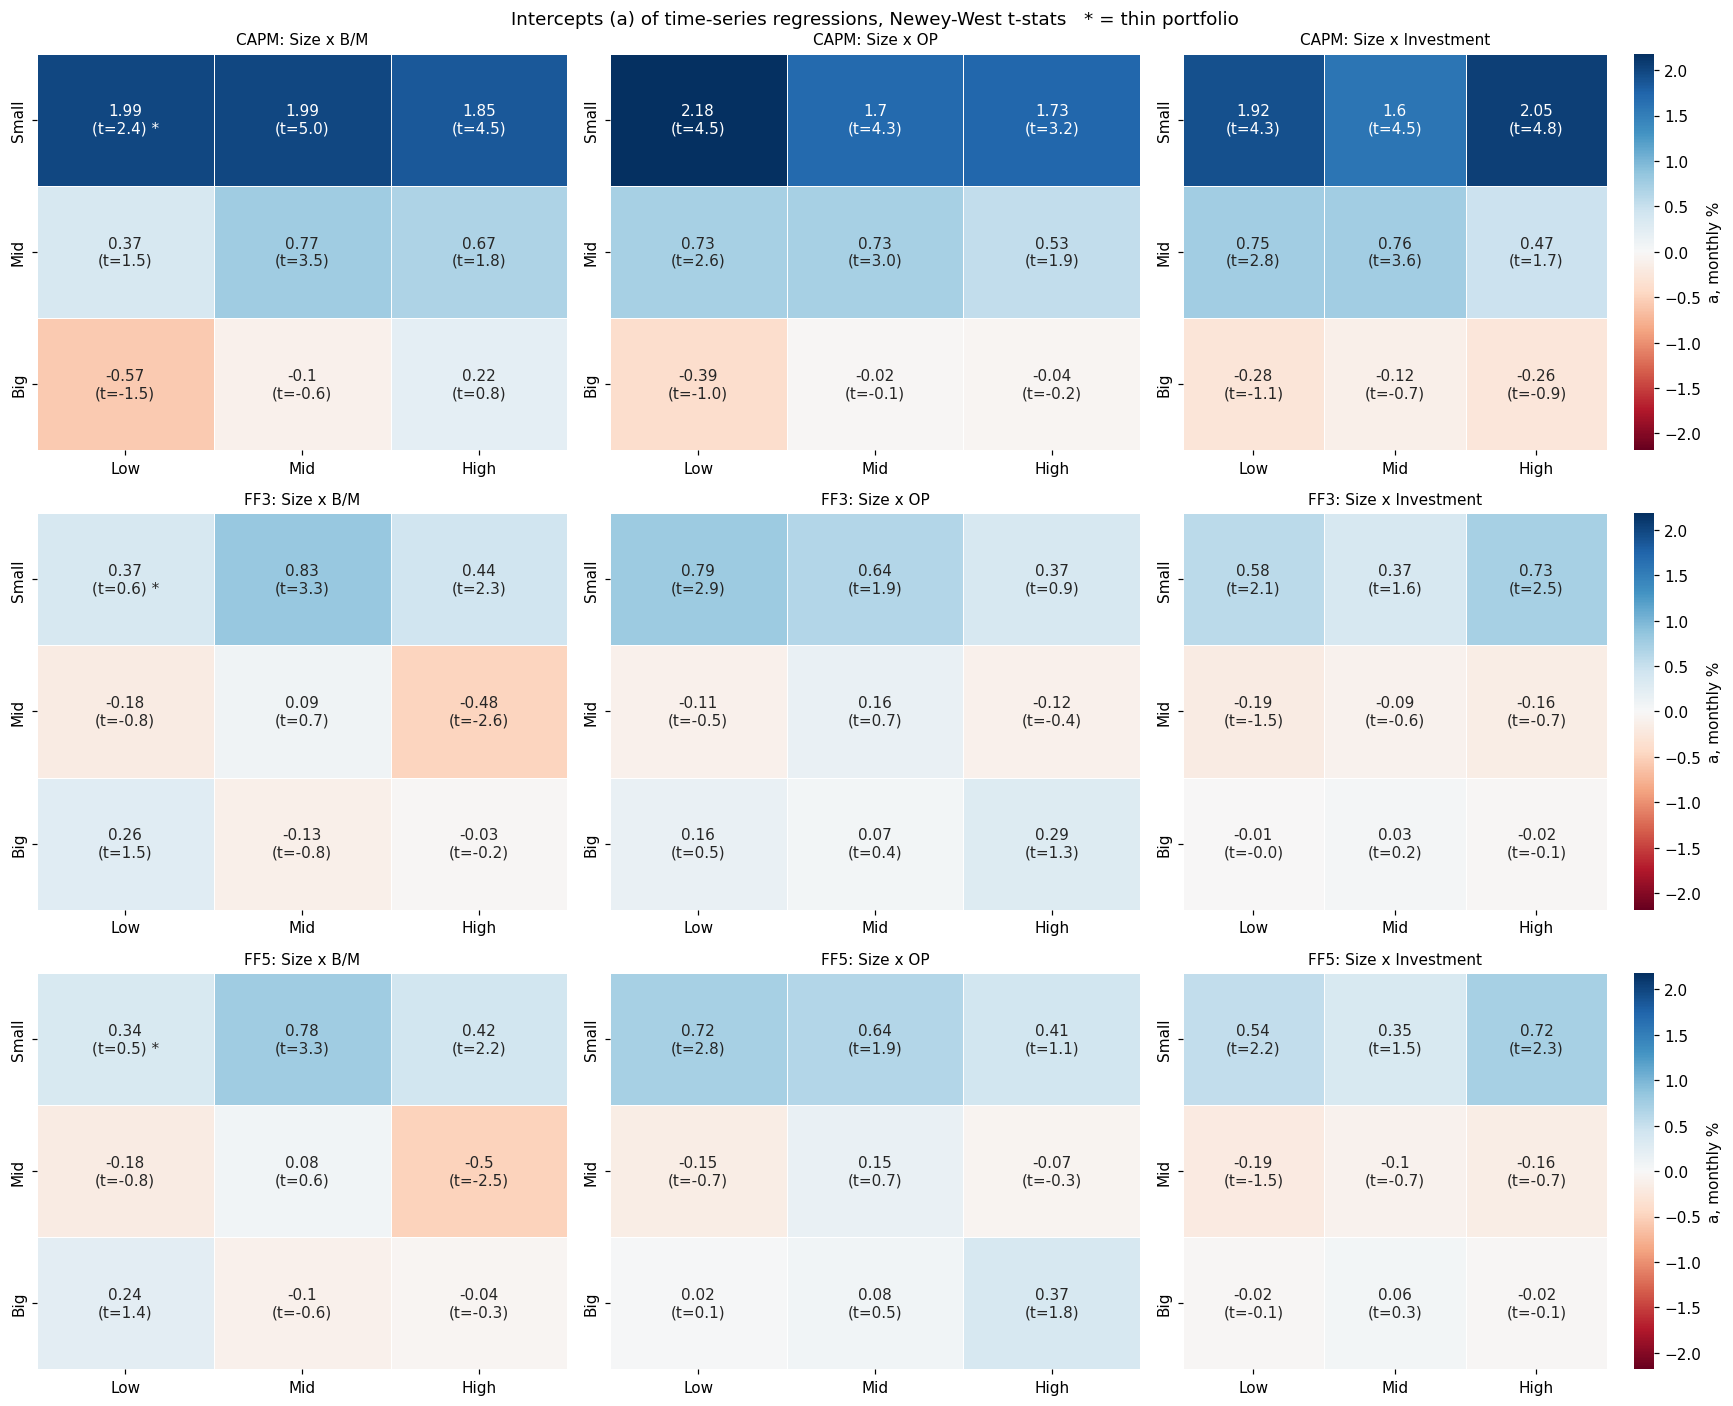

In [35]:
# 3.3 Plot - intercept heatmaps (rows = models, columns = sorts)
# Blue = positive intercept, red = negative, white = zero

sort_titles = {"BM": "Size x B/M", "OP": "Size x OP", "INV": "Size x Investment"}

# Same colour scale in every panel so models can be compared
color_limit = reg_results["abs_a_%"].max()

fig, axes = plt.subplots(len(MODELS), len(SORTS), figsize=(16, 13))

for i, model_name in enumerate(MODELS):
    for j, sort_type in enumerate(SORTS):

        ax = axes[i, j]
        s = reg_results[(reg_results["model"] == model_name) &
                        (reg_results["sort_type"] == sort_type)]

        a_grid = s.pivot(index="size_group", columns="char_group", values="a_monthly_%")
        t_grid = s.pivot(index="size_group", columns="char_group", values="t_a")
        id_grid = s.pivot(index="size_group", columns="char_group", values="portfolio_id")

        # Cell text: intercept, NW t-stat below it, * for flagged portfolios
        annot = a_grid.round(2).astype(str) + "\n(t=" + t_grid.round(1).astype(str) + ")"
        annot = annot.where(~id_grid.isin(FLAGGED_PORTFOLIOS), annot + " *")

        a_grid.index = [SIZE_LABELS[k] for k in a_grid.index]
        a_grid.columns = [CHAR_LABELS[k] for k in a_grid.columns]

        sns.heatmap(a_grid, annot=annot.values, fmt="", cmap="RdBu", center=0,
                    vmin=-color_limit, vmax=color_limit, linewidths=0.5,
                    cbar=(j == len(SORTS) - 1), cbar_kws={"label": "a, monthly %"}, ax=ax)

        ax.set_title(f"{model_name}: {sort_titles[sort_type]}", fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")

fig.suptitle("Intercepts (a) of time-series regressions, Newey-West t-stats   "
             "* = thin portfolio", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_3_intercept_heatmaps.png", bbox_inches="tight", dpi=300)
plt.show()

## Inferences: Intercepts (a) of time-series regressions

*a = monthly % excess return not explained by factor exposures; t = Newey-West t-stat;
significant if |t| > 2. Averages below are computed from the rounded plot values
(exact figures in `phase_3_intercept_summary.csv`).*

| Model | Significant intercepts | Average \|a\| (monthly %) |
|---|:---:|:---:|
| CAPM | 14 of 27 | ≈ 0.92 |
| FF3 | 6 of 27 | ≈ 0.29 |
| FF5 | 6 of 27 | ≈ 0.28 |

**1. CAPM fails on small and mid-cap stocks.**
- All 9 Small portfolios have a = 1.60% to 2.18% per month (≈ 19–26% p.a.), t = 2.4 to 5.0.
- 5 Mid portfolios are significant, a = 0.73% to 0.77% (t = 2.6 to 3.6).
- Big portfolios are close to zero, a = −0.57% to 0.22%, all |t| ≤ 1.5: the market
  factor is essentially the big stocks.

**2. FF3 removes about 70% of the pricing error.**
- Average |a| falls from ≈ 0.92% to ≈ 0.29%; significant intercepts fall from 14 to 6.
- Small-row intercepts drop to 0.37% to 0.83%. SMB does most of this work.

**3. FF5 adds almost nothing over FF3 on intercepts.**
- The same 6 portfolios stay significant, and average |a| changes only from ≈ 0.29% to ≈ 0.28%.
- Reason: RMW (−0.24%/month) and CMA (+0.08%/month) have near-zero premiums, so even
  large loadings change expected returns very little.
  - OP_S3_C1: RMW loading −0.83 × −0.24% ≈ +0.20%, so a falls from 0.16% to 0.02%.
  - OP_S3_C3: loading +0.43 × −0.24% ≈ −0.10%, so a rises from 0.29% to 0.37%.

**4. The unexplained returns are concentrated in small stocks (FF5).**
- Small-row average a ≈ 0.55% per month (≈ 6.6% p.a.).
- Significant: BM_S1_C2 (0.78%, t = 3.3), OP_S1_C1 (0.72%, t = 2.8), INV_S1_C3 (0.72%, t = 2.3),
  INV_S1_C1 (0.54%, t = 2.2), BM_S1_C3 (0.42%, t = 2.2).
- Both conservative (0.54%) and aggressive (0.72%) small portfolios are positive, so this is a
  size-level error, not an investment or profitability one.
- Likely contributor: survivorship bias in the current-constituent universe, which is strongest
  among the smallest stocks (bottom 30% here, versus the bottom 50% in SMB).

**5. One significant negative intercept: Mid value (BM_S2_C3), a = −0.50%, t = −2.5.**
Mid-cap value stocks earned less than their HML loading (0.45) predicts.

**6. Big stocks are priced well by FF3 and FF5.**
All 9 Big intercepts lie between −0.10% and 0.37%, none significant (max |t| = 1.8).

**7. The flagged thin portfolio (BM_S1_C1) is not informative.**
a = 0.34% with t = 0.5 under FF5; with R² of only 0.48, its insignificance reflects noise,
not a good fit.

**Comparison with FF (2015):** in the US, FF5's main failure is a *negative* intercept for small,
growth, low-profitability, high-investment stocks. In this sample, the failure is a *positive*
intercept across small stocks generally.

**Caveat:** these are 27 separate t-tests. The joint test that all intercepts are zero is GRS (Step 4).

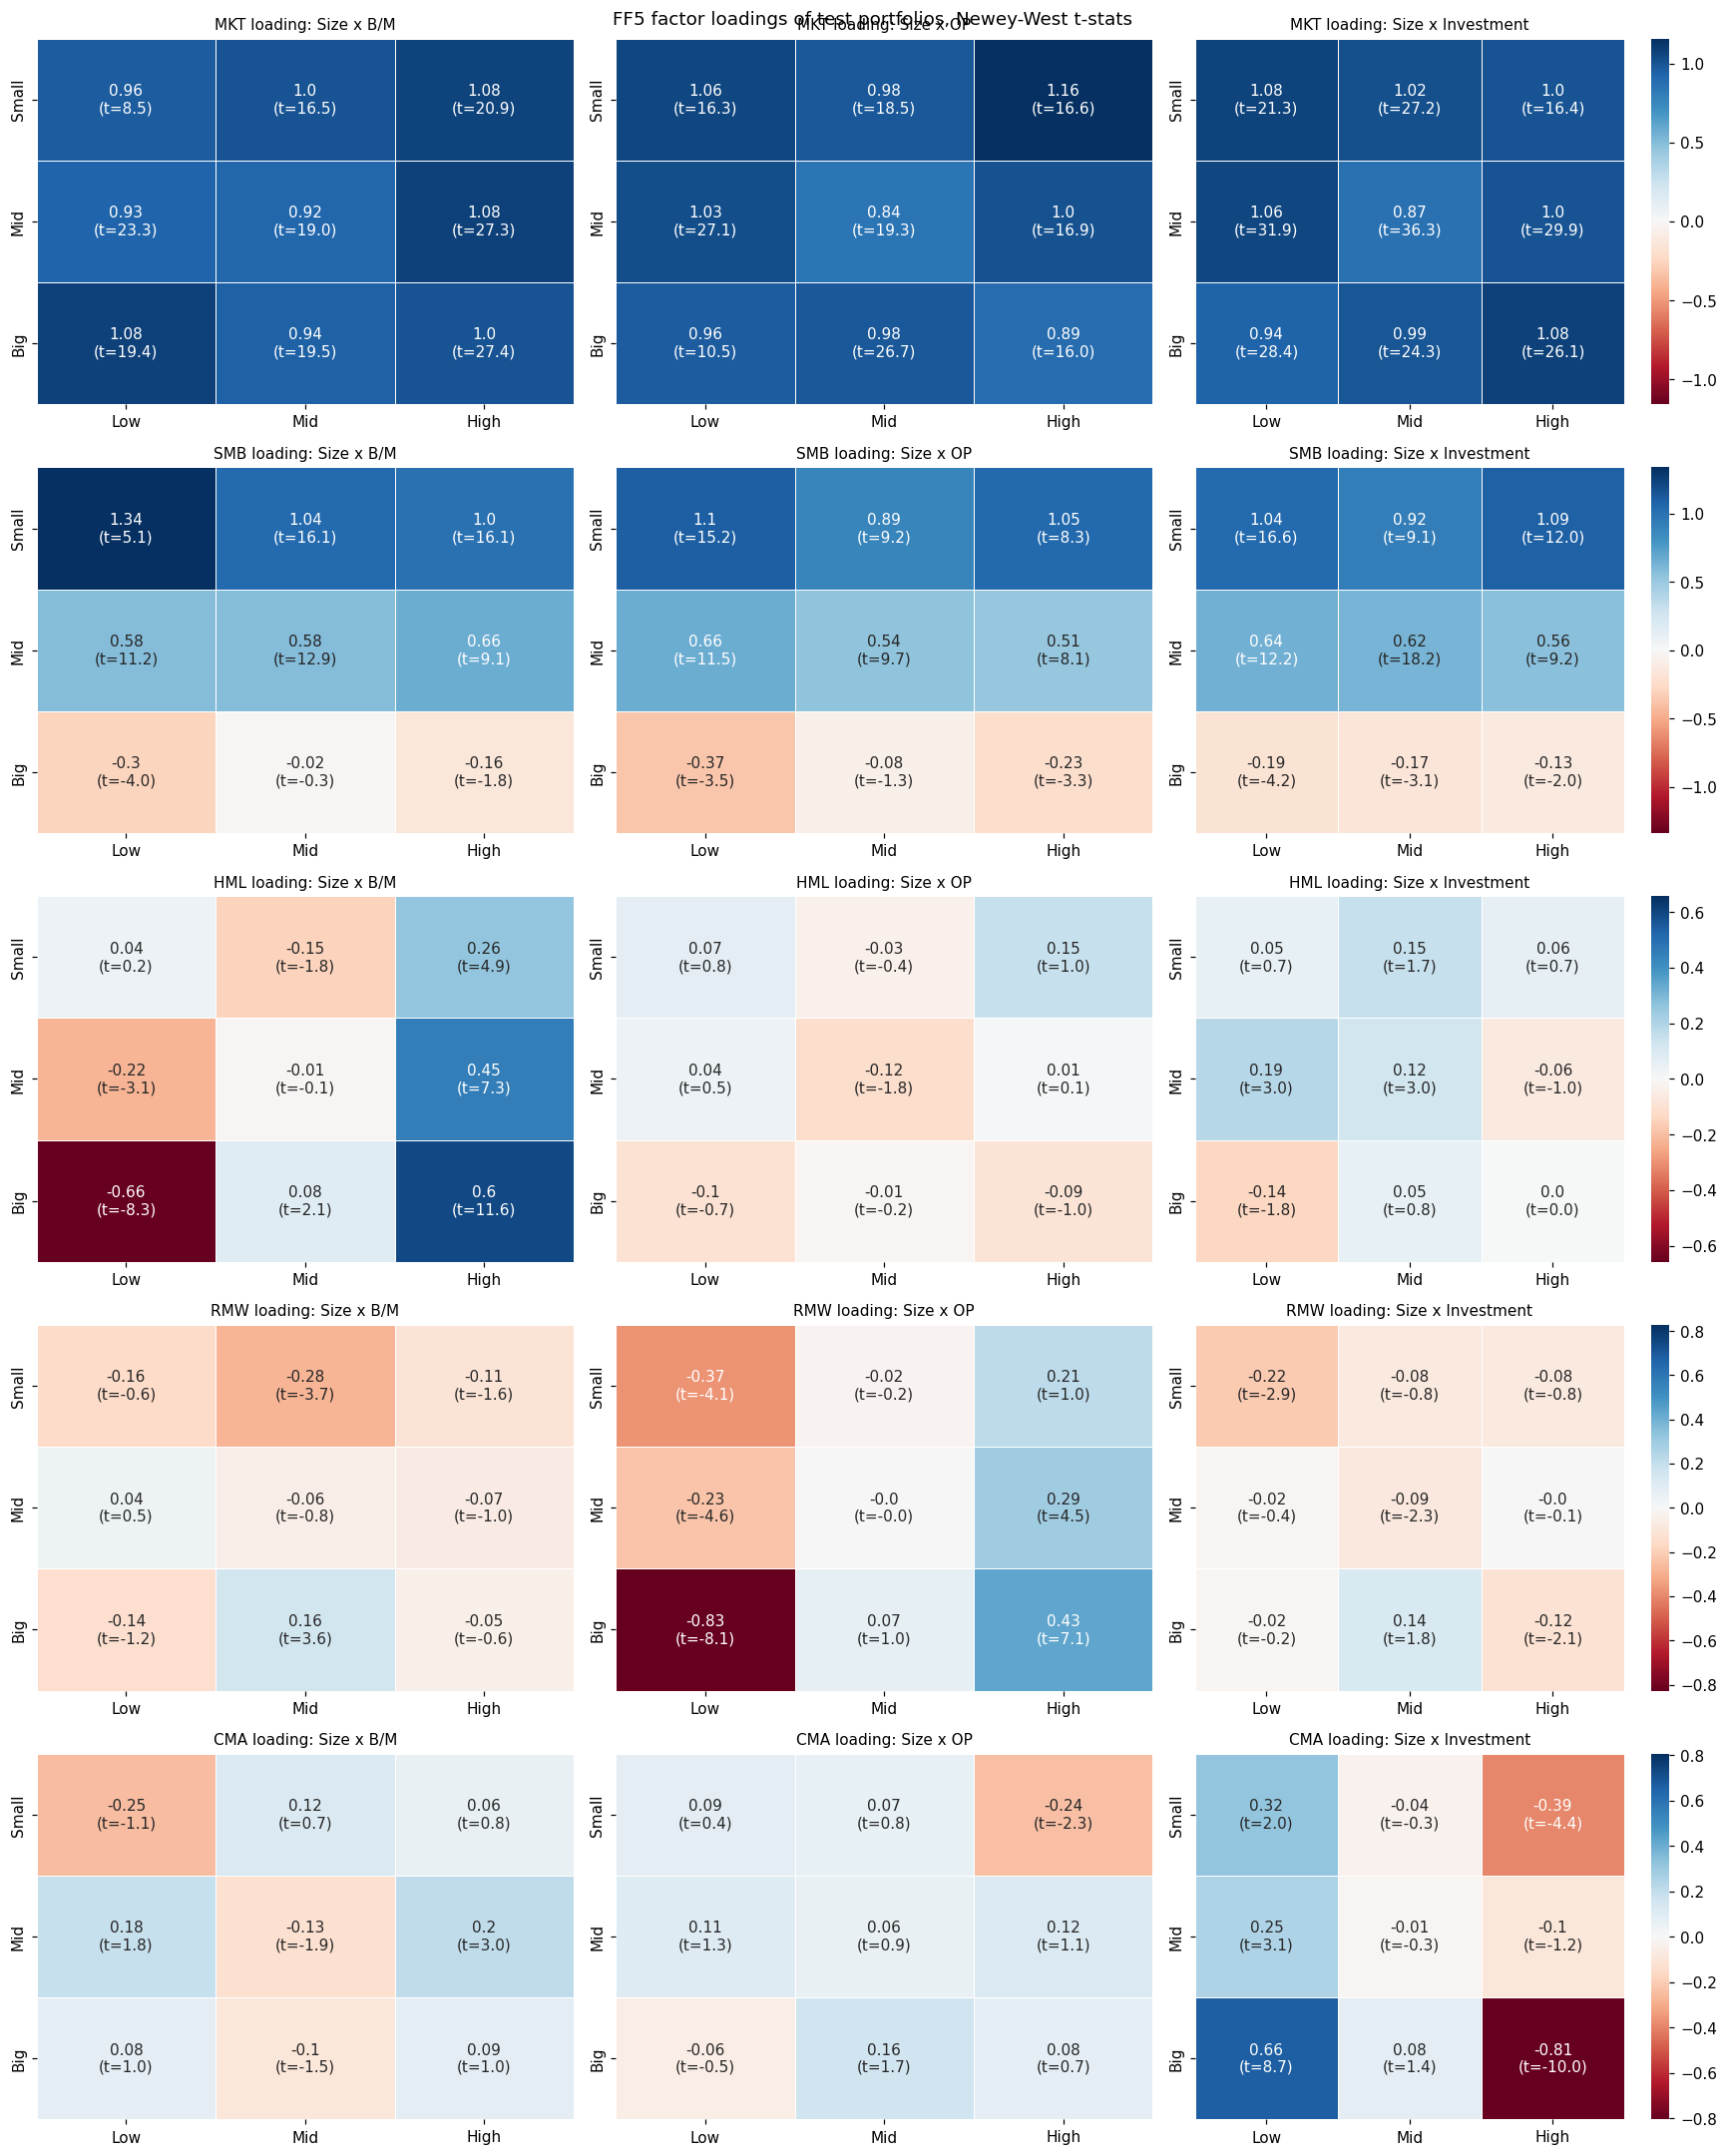

In [36]:
# 3.4 Plot - FF5 loading heatmaps (rows = factors, columns = sorts)

ff5 = reg_results[reg_results["model"] == "FF5"]

fig, axes = plt.subplots(len(FACTOR_COLS), len(SORTS), figsize=(16, 20))

for i, f in enumerate(FACTOR_COLS):

    # Same colour scale across the three sorts for each factor
    f_limit = ff5[f"b_{f}"].abs().max()

    for j, sort_type in enumerate(SORTS):

        ax = axes[i, j]
        s = ff5[ff5["sort_type"] == sort_type]

        b_grid = s.pivot(index="size_group", columns="char_group", values=f"b_{f}")
        t_grid = s.pivot(index="size_group", columns="char_group", values=f"t_{f}")

        annot = b_grid.round(2).astype(str) + "\n(t=" + t_grid.round(1).astype(str) + ")"

        b_grid.index = [SIZE_LABELS[k] for k in b_grid.index]
        b_grid.columns = [CHAR_LABELS[k] for k in b_grid.columns]

        sns.heatmap(b_grid, annot=annot.values, fmt="", cmap="RdBu", center=0,
                    vmin=-f_limit, vmax=f_limit, linewidths=0.5,
                    cbar=(j == len(SORTS) - 1), ax=ax)

        ax.set_title(f"{f} loading: {sort_titles[sort_type]}", fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")

fig.suptitle("FF5 factor loadings of test portfolios, Newey-West t-stats", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_4_ff5_loading_heatmaps.png", bbox_inches="tight", dpi=300)
plt.show()

## Inferences: FF5 factor loading heatmaps

*Each number is a loading: how much the portfolio's return moves when the factor moves by 1%.
Brackets show Newey-West t-stats. Each factor should load in a clean pattern across its own sort.*

**1. MKT: every portfolio moves about one-for-one with the market.**
Loadings range from 0.84 to 1.16, all with t > 8.

**2. SMB: clean size pattern in all three sorts.**
Loadings fall from Small (0.89 to 1.34) to Mid (0.51 to 0.66) to Big (−0.02 to −0.37).
Big loadings are negative because big stocks sit on SMB's short side.

**3. HML: clean value pattern in the B/M sort.**
Loadings rise from Low (Growth) to High B/M (value) in every row: Big −0.66 → 0.60, Mid −0.22 → 0.45,
Small 0.04 → 0.26. In the OP and INV sorts, HML loadings are small (mostly |b| < 0.2) and
largely insignificant, unlike the US, where value overlaps strongly with conservative investment.
This matches the low HML–CMA correlation (0.31).

**4. RMW: clean profitability pattern in the OP sort.**
Loadings rise from Weak to Robust in every row: Big −0.83 → 0.43, Mid −0.23 → 0.29,
Small −0.37 → 0.21.

**5. CMA: clean investment pattern in the INV sort.**
Loadings fall from Conservative to Aggressive in every row: Big 0.66 → −0.81,
Mid 0.25 → −0.10, Small 0.32 → −0.39.

**6. Patterns are strongest among Big stocks.**
The largest spreads (HML 1.26, RMW 1.26, CMA 1.47 between the extreme Big portfolios) occur in the
Big row. This is consistent with the Phase 2 convention of computing characteristic breakpoints
from Big stocks; Small portfolios show weaker, noisier patterns.

**Conclusion:** each factor loads strongly and in the expected direction on its own sort, which
confirms that the Phase 2 factor construction captures what each sort is designed to capture.

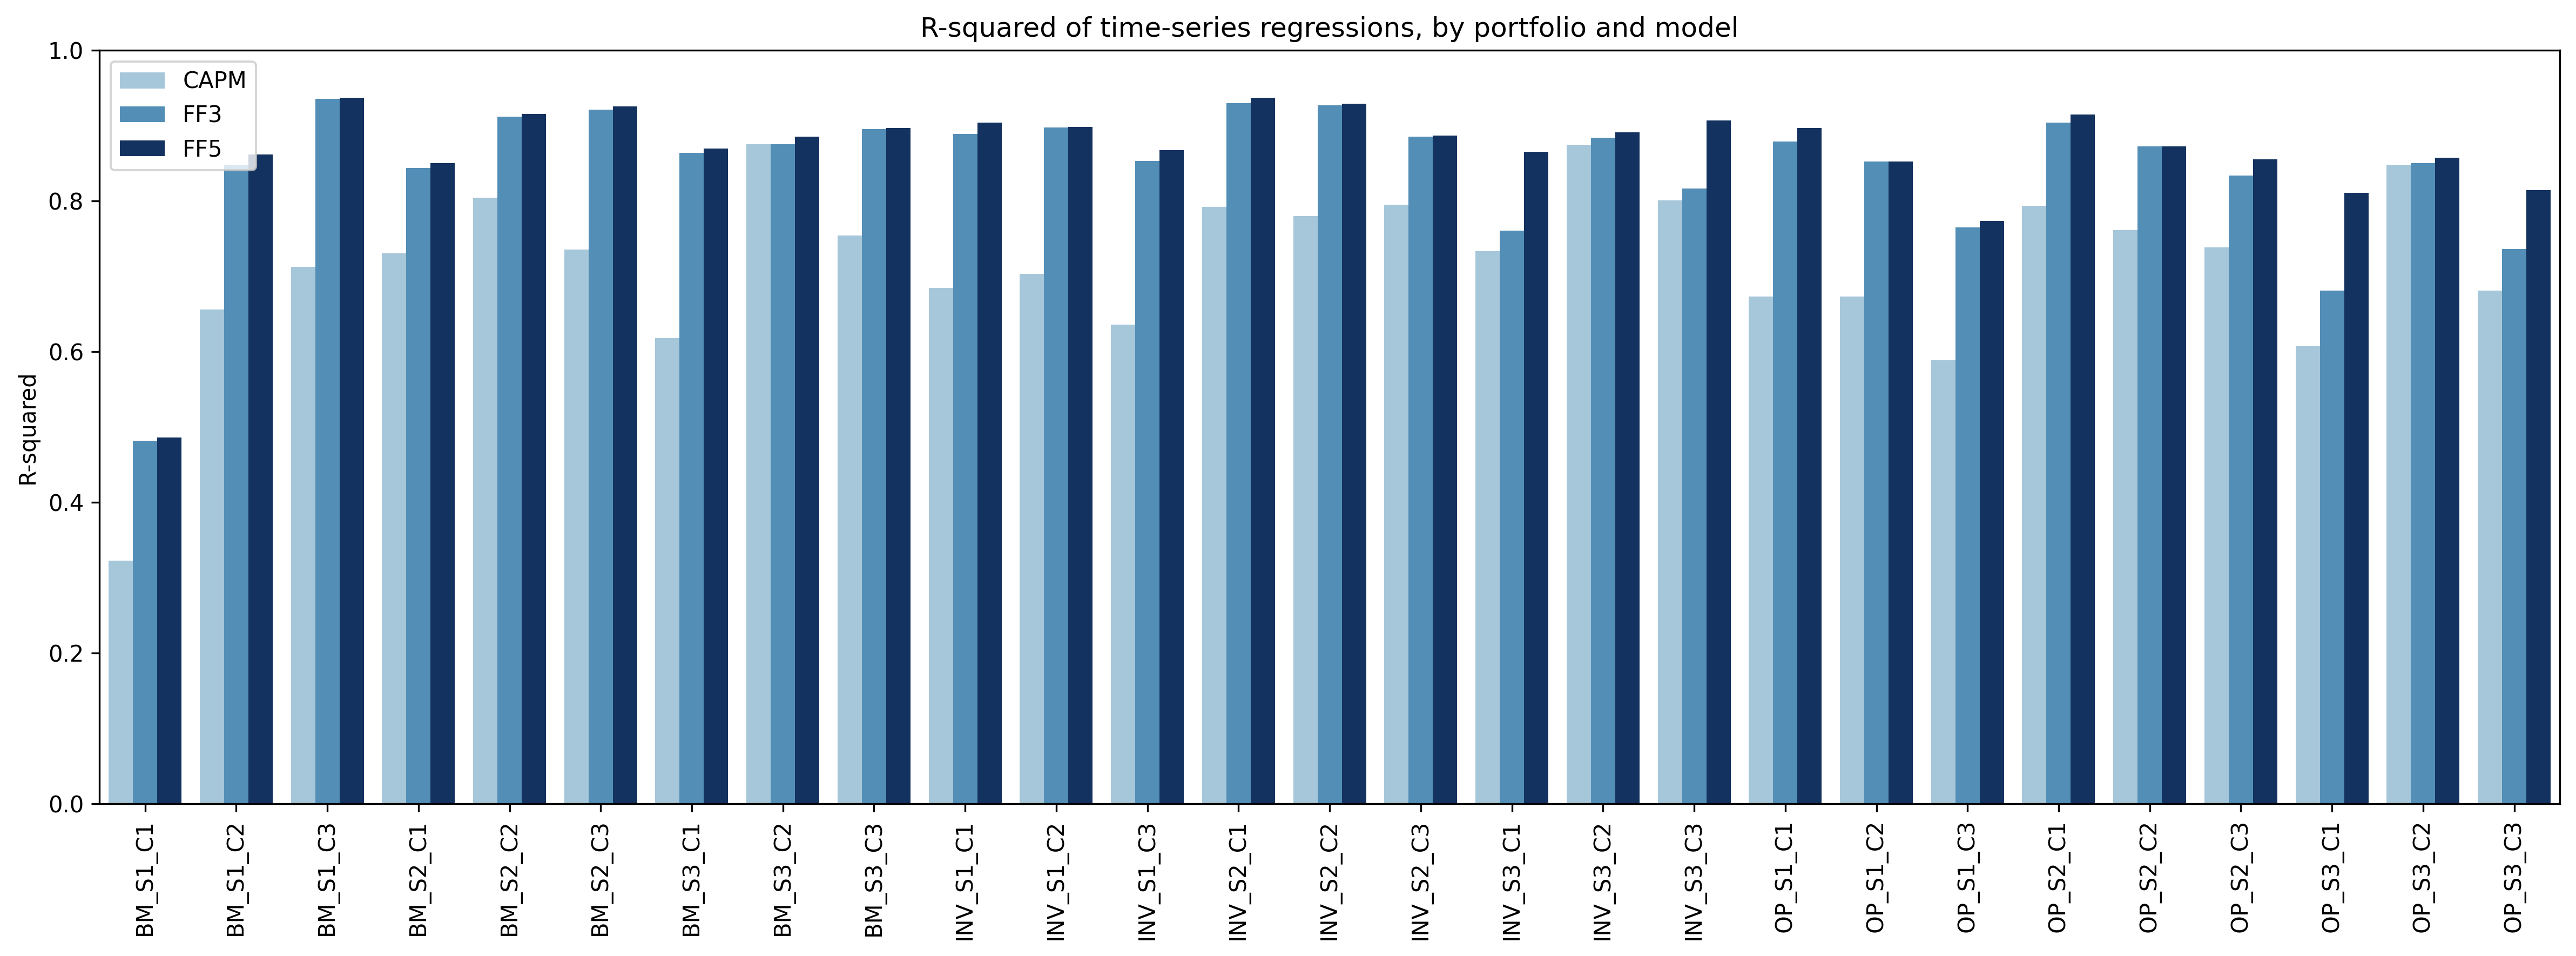

In [37]:
# 3.5 Plot - R-squared of each portfolio, by model

model_colors = {"CAPM": "#9ecae1", "FF3": "#4292c6", "FF5": "#08306b"}

fig, ax = plt.subplots(figsize=(16, 6), dpi=300)

sns.barplot(
    data=reg_results,
    x="portfolio_id",
    y="r_squared",
    hue="model",
    hue_order=list(MODELS),
    palette=model_colors,
    order=PORTFOLIO_IDS,
    ax=ax,
)

ax.set_ylim(0, 1)
ax.set_title("R-squared of time-series regressions, by portfolio and model")
ax.set_xlabel("")
ax.set_ylabel("R-squared")
ax.tick_params(axis="x", rotation=90)
ax.legend(title="")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_5_r_squared_by_model.png", bbox_inches="tight")
plt.show()

## Inferences: R² by portfolio and model

*R² = share of a portfolio's month-to-month return variation explained by the factors.*

**1. CAPM explains big portfolios best.**
CAPM R² ranges from 0.32 (BM_S1_C1) to about 0.87 (BM_S3_C2, INV_S3_C2). Big portfolios
reach 0.73 to 0.87, while most Small portfolios stay between 0.6 and 0.7, because the
value-weighted market factor is dominated by big stocks.

**2. Adding SMB and HML (FF3) gives the largest gain, mainly for small and mid portfolios.**
For example, BM_S1_C3 rises from 0.71 to 0.94 and INV_S1_C1 from 0.68 to 0.89.

**3. FF5 adds little over FF3, except for the extreme Big portfolios of the OP and INV sorts.**
OP_S3_C1: 0.68 → 0.81; OP_S3_C3: 0.74 → 0.81; INV_S3_C1: 0.76 → 0.86; INV_S3_C3: 0.82 → 0.91.
These are exactly the portfolios with the largest RMW and CMA loadings.

**4. FF5 explains most of the variation in almost every portfolio.**
Excluding the flagged portfolio, FF5 R² ranges from about 0.77 (OP_S1_C3) to 0.94 (BM_S1_C3, INV_S2_C1).

**5. The flagged thin portfolio (BM_S1_C1) stays poorly explained.**
Its FF5 R² is only 0.48, reflecting stock-specific noise (a single stock, AFFLE, in 2020–21).

**Caveat:** a high R² shows co-movement, not correct pricing. RMW and CMA raise R² but barely
change the intercepts, because their premiums are near zero in this sample.

In [38]:
# 3.6 Save results for Step 4 and Phases 4-5

reg_results.to_csv(OUTPUT_DIR / "phase_3_regression_results.csv", index=False)
residuals_df.to_csv(OUTPUT_DIR / "phase_3_residuals.csv", index=False)
intercept_summary.to_csv(OUTPUT_DIR / "phase_3_intercept_summary.csv", index=False)

print("Saved:")
print(" - phase_3_regression_results.csv  (81 rows: 27 portfolios x 3 models)")
print(" - phase_3_residuals.csv           (", len(residuals_df), "rows )")
print(" - phase_3_intercept_summary.csv")

Saved:
 - phase_3_regression_results.csv  (81 rows: 27 portfolios x 3 models)
 - phase_3_residuals.csv           ( 9720 rows )
 - phase_3_intercept_summary.csv


In [39]:
# ==========================================================
# STEP 4: Judge the Model the FF-way
# ==========================================================

In [40]:
# 4.0 Load test portfolios and line them up with the factors

test_ports_df = pd.read_csv(OUTPUT_DIR / "phase_3_test_portfolios.csv", parse_dates=["date"])

excess_wide = test_ports_df.pivot(index="date", columns="portfolio_id", values="excess_ret")
excess_wide = excess_wide.sort_index()
excess_wide = excess_wide[excess_wide.index.isin(df_factors.index)]

factors_aligned = df_factors.loc[excess_wide.index, FACTOR_COLS]

port_info = (
    test_ports_df[["portfolio_id", "sort_type", "size_group", "char_group"]]
    .drop_duplicates()
    .set_index("portfolio_id")
)

mean_excess = excess_wide.mean()     # average monthly excess return of each portfolio

# Sets of portfolios tested jointly
bm_ids = [p for p in excess_wide.columns if p.startswith("BM_")]
TEST_SETS = {
    "BM": bm_ids,
    "OP": [p for p in excess_wide.columns if p.startswith("OP_")],
    "INV": [p for p in excess_wide.columns if p.startswith("INV_")],
    "ALL": list(excess_wide.columns),
    "BM_excl_flagged": [p for p in bm_ids if p not in FLAGGED_PORTFOLIOS],   # sensitivity check
}

print("Months:", len(excess_wide))                                  # expect 120
print("Missing values:", excess_wide.isna().sum().sum())            # must be 0
print({name: len(ids) for name, ids in TEST_SETS.items()})          # 9, 9, 9, 27, 8

Months: 120
Missing values: 0
{'BM': 9, 'OP': 9, 'INV': 9, 'ALL': 27, 'BM_excl_flagged': 8}


In [41]:
# 4.1 Helper functions

def time_series_stats(excess, factors):
    """
    Regress every portfolio on the factors.
    Returns intercept, its Newey-West standard error, R-squared, and residuals.
    """
    X = sm.add_constant(factors)
    rows, residuals = [], {}

    for pid in excess.columns:
        fit = sm.OLS(excess[pid], X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows.append({
            "portfolio_id": pid,
            "a": fit.params["const"],
            "se_a_nw": fit.bse["const"],
            "t_a_nw": fit.tvalues["const"],
            "r_squared": fit.rsquared,
        })
        residuals[pid] = fit.resid

    return pd.DataFrame(rows).set_index("portfolio_id"), pd.DataFrame(residuals)


def grs_test(a, residuals, factors):
    """
    Gibbons-Ross-Shanken (1989) test that all intercepts are zero.
    GRS = (T-N-L)/N * (a' S^-1 a) / (1 + mu' W^-1 mu)  ~  F(N, T-N-L)
    """
    T, N = residuals.shape
    L = factors.shape[1]

    sigma = residuals.T @ residuals / T              # residual covariance (N x N)
    mu = factors.mean(axis=0)                        # average factor returns
    f_dev = factors - mu
    omega = f_dev.T @ f_dev / T                      # factor covariance (L x L)

    a_term = a @ np.linalg.solve(sigma, a)
    mu_term = mu @ np.linalg.solve(omega, mu)

    grs = (T - N - L) / N * a_term / (1 + mu_term)
    p_value = stats.f.sf(grs, N, T - N - L)
    return grs, p_value


def nw_wald_test(excess, factors):
    """
    Robustness check: Wald test that all intercepts are zero,
    using a Newey-West covariance of the intercepts across portfolios.
    Returns NaN when there are too many parameters for the number of months.
    """
    Y = excess.values
    T, N = Y.shape
    X = np.column_stack([np.ones(T), factors])
    K = X.shape[1]

    if N * K >= T:          # covariance matrix cannot be estimated reliably
        return np.nan, np.nan

    B = np.linalg.lstsq(X, Y, rcond=None)[0]         # K x N coefficients
    E = Y - X @ B                                     # residuals

    # Moment conditions e_t * x_t for every portfolio, stacked (T x N*K)
    G = np.einsum("tn,tk->tnk", E, X).reshape(T, N * K)

    # Newey-West long-run covariance with Bartlett weights
    S = G.T @ G / T
    for lag in range(1, NW_LAGS + 1):
        weight = 1 - lag / (NW_LAGS + 1)
        gamma = G[lag:].T @ G[:-lag] / T
        S += weight * (gamma + gamma.T)

    D = np.kron(np.eye(N), np.linalg.inv(X.T @ X / T))
    V = D @ S @ D / T                                 # covariance of all coefficients

    a_index = [n * K for n in range(N)]               # positions of the intercepts
    V_a = V[np.ix_(a_index, a_index)]
    a = B[0]

    wald = a @ np.linalg.solve(V_a, a)
    p_value = stats.chi2.sf(wald, N)
    return wald, p_value


def ff_summary(port_stats, mean_ret):
    """
    FF (2015) Table 5 style summary statistics for one set of portfolios.
    r_bar = portfolio's average excess return minus the cross-sectional average.
    """
    a = port_stats["a"]
    r_bar = mean_ret - mean_ret.mean()

    return {
        "avg_abs_a": a.abs().mean() * 100,                               # monthly %
        "abs_a_to_abs_r": a.abs().mean() / r_bar.abs().mean(),
        "share_unexplained": (a ** 2).mean() / (r_bar ** 2).mean(),
        "sampling_error_share": (port_stats["se_a_nw"] ** 2).mean() / (a ** 2).mean(),
        "avg_R2": port_stats["r_squared"].mean(),
    }

In [42]:
# 4.2 GRS test, NW Wald test and summary statistics for every model and every set of test portfolios

comparison_rows = []
port_stats_list = []

for model_name, model_factors in MODELS.items():

    f = factors_aligned[model_factors]

    # Per-portfolio regressions (identical whichever set a portfolio is tested in)
    port_stats, residuals = time_series_stats(excess_wide, f)

    keep = port_stats.copy()
    keep["model"] = model_name
    port_stats_list.append(keep.reset_index())

    for set_name, ids in TEST_SETS.items():

        s = port_stats.loc[ids]
        grs, grs_p = grs_test(s["a"].values, residuals[ids].values, f.values)
        wald, wald_p = nw_wald_test(excess_wide[ids], f.values)

        comparison_rows.append({
            "model": model_name,
            "sort_type": set_name,
            "n_portfolios": len(ids),
            "GRS": grs,
            "p_value": grs_p,
            "NW_wald": wald,
            "NW_wald_p_value": wald_p,
            **ff_summary(s, mean_excess[ids]),
        })

model_comparison = pd.DataFrame(comparison_rows)

# Columns in a fixed order (required columns first)
model_comparison = model_comparison[
    ["model", "sort_type", "GRS", "p_value", "avg_abs_a", "avg_R2", "share_unexplained",
     "n_portfolios", "abs_a_to_abs_r", "sampling_error_share", "NW_wald", "NW_wald_p_value"]
]

display(model_comparison.round(3))

,model,sort_type,GRS,p_value,avg_abs_a,avg_R2,share_unexplained,n_portfolios,abs_a_to_abs_r,sampling_error_share,NW_wald,NW_wald_p_value
0,CAPM,BM,4.133,0.000,0.950,0.690,1.585,9,1.173,0.120,37.140,0.000
1,CAPM,OP,3.511,0.001,0.895,0.707,1.605,9,1.149,0.093,32.069,0.000
2,CAPM,INV,3.388,0.001,0.911,0.755,1.577,9,1.170,0.074,41.107,0.000
3,CAPM,ALL,1.407,0.118,0.919,0.717,1.588,27,1.166,0.096,122.818,0.000
4,CAPM,BM_excl_flagged,4.690,0.000,0.820,0.736,1.407,8,1.128,0.093,36.975,0.000
5,FF3,BM,2.124,0.033,0.313,0.842,0.169,9,0.387,0.503,22.423,0.008
6,FF3,OP,1.737,0.089,0.301,0.819,0.177,9,0.386,0.505,22.614,0.007
7,FF3,INV,1.538,0.144,0.241,0.871,0.142,9,0.309,0.420,32.670,0.000
8,FF3,ALL,0.846,0.681,0.285,0.844,0.163,27,0.362,0.480,140.016,0.000
9,FF3,BM_excl_flagged,2.412,0.019,0.307,0.887,0.196,8,0.422,0.237,22.298,0.004


In [43]:
# 4.3 Problem portfolios - where FF5 fails

port_stats_all = pd.concat(port_stats_list, ignore_index=True)
port_stats_all = port_stats_all.merge(port_info, left_on="portfolio_id", right_index=True)

port_stats_all["a_monthly_%"] = port_stats_all["a"] * 100
port_stats_all["actual_%"] = port_stats_all["portfolio_id"].map(mean_excess) * 100
port_stats_all["predicted_%"] = port_stats_all["actual_%"] - port_stats_all["a_monthly_%"]
port_stats_all["flagged"] = port_stats_all["portfolio_id"].isin(FLAGGED_PORTFOLIOS)
port_stats_all["size"] = port_stats_all["size_group"].map(SIZE_LABELS)
port_stats_all["char"] = port_stats_all["char_group"].map(CHAR_LABELS)

# FF5 loadings from Step 3, to describe what each problem portfolio is exposed to
reg_results_df = pd.read_csv(OUTPUT_DIR / "phase_3_regression_results.csv")
ff5_loadings = reg_results_df[reg_results_df["model"] == "FF5"][
    ["portfolio_id"] + [f"b_{f}" for f in FACTOR_COLS]
]

problem_portfolios = (
    port_stats_all[(port_stats_all["model"] == "FF5") &
                   (port_stats_all["t_a_nw"].abs() > 2)]
    .merge(ff5_loadings, on="portfolio_id")
    .sort_values("a_monthly_%", key=abs, ascending=False)
)

display(problem_portfolios[
    ["portfolio_id", "sort_type", "size", "char", "actual_%", "predicted_%",
     "a_monthly_%", "t_a_nw", "r_squared", "flagged"] + [f"b_{f}" for f in FACTOR_COLS]
].round(2))

,portfolio_id,sort_type,size,char,actual_%,predicted_%,a_monthly_%,t_a_nw,r_squared,flagged,b_MKT,b_SMB,b_HML,b_RMW,b_CMA
0,BM_S1_C2,BM,Small,Mid,2.53,1.75,0.78,3.35,0.86,False,1.00,1.04,-0.15,-0.28,0.12
5,OP_S1_C1,OP,Small,Low,2.78,2.06,0.72,2.80,0.90,False,1.06,1.10,0.07,-0.37,0.09
4,INV_S1_C3,INV,Small,High,2.62,1.90,0.72,2.31,0.87,False,1.00,1.09,0.06,-0.08,-0.39
3,INV_S1_C1,INV,Small,Low,2.50,1.96,0.54,2.19,0.90,False,1.08,1.04,0.05,-0.22,0.32
2,BM_S2_C3,BM,Mid,High,1.26,1.75,-0.50,-2.54,0.93,False,1.08,0.66,0.45,-0.07,0.20
1,BM_S1_C3,BM,Small,High,2.45,2.03,0.42,2.23,0.94,False,1.08,1.00,0.26,-0.11,0.06


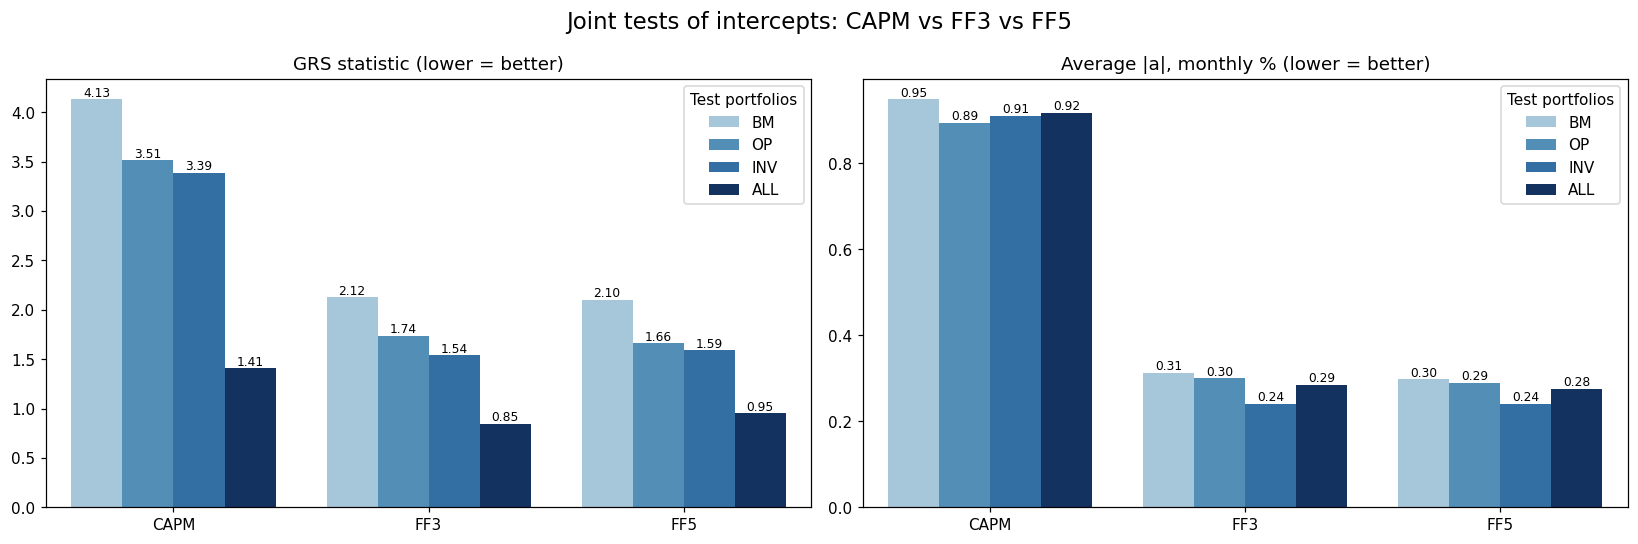

In [44]:
# 4.4 Plot - GRS statistic and average |a| by model

plot_sets = ["BM", "OP", "INV", "ALL"]
set_colors = {"BM": "#9ecae1", "OP": "#4292c6", "INV": "#2171b5", "ALL": "#08306b"}

plot_df = model_comparison[model_comparison["sort_type"].isin(plot_sets)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, metric, title in zip(
    axes,
    ["GRS", "avg_abs_a"],
    ["GRS statistic (lower = better)", "Average |a|, monthly % (lower = better)"],
):
    sns.barplot(data=plot_df, x="model", y=metric, hue="sort_type",
                order=list(MODELS), hue_order=plot_sets, palette=set_colors, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend(title="Test portfolios")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8)

fig.suptitle("Joint tests of intercepts: CAPM vs FF3 vs FF5", fontsize=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4_4_grs_and_avg_abs_a.png", bbox_inches="tight", dpi=300)
plt.show()

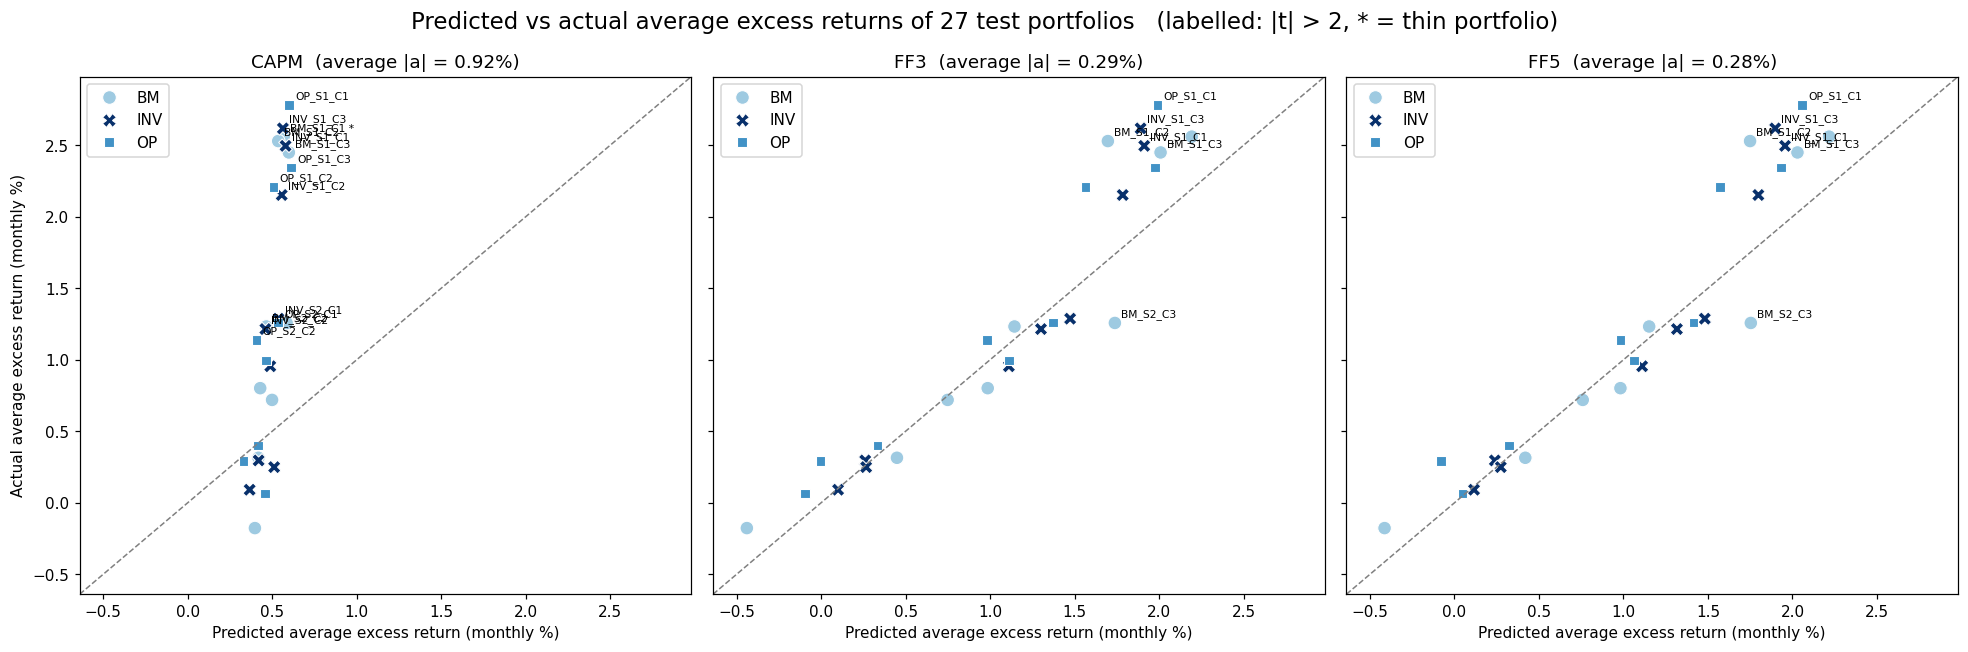

In [45]:
# 4.5 Plot - predicted vs actual average excess return
# Predicted = loadings x average factor returns = actual - a
# Points on the 45-degree line are priced perfectly

sort_colors = {"BM": "#9ecae1", "OP": "#4292c6", "INV": "#08306b"}

all_values = pd.concat([port_stats_all["actual_%"], port_stats_all["predicted_%"]])
lims = [all_values.min() - 0.2, all_values.max() + 0.2]

fig, axes = plt.subplots(1, len(MODELS), figsize=(18, 6), sharex=True, sharey=True)

for ax, model_name in zip(axes, MODELS):

    s = port_stats_all[port_stats_all["model"] == model_name]

    sns.scatterplot(data=s, x="predicted_%", y="actual_%", hue="sort_type",
                    style="sort_type", palette=sort_colors, s=80, ax=ax)

    ax.plot(lims, lims, color="grey", linestyle="--", linewidth=1)   # 45-degree line

    # Label portfolios whose intercept is significant (|t| > 2)
    for _, row in s[s["t_a_nw"].abs() > 2].iterrows():
        label = row["portfolio_id"] + (" *" if row["flagged"] else "")
        ax.annotate(label, (row["predicted_%"], row["actual_%"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7)

    avg_abs_a = s["a_monthly_%"].abs().mean()
    ax.set_title(f"{model_name}  (average |a| = {avg_abs_a:.2f}%)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Predicted average excess return (monthly %)")
    ax.set_ylabel("Actual average excess return (monthly %)")
    ax.legend(title="")

fig.suptitle("Predicted vs actual average excess returns of 27 test portfolios   "
             "(labelled: |t| > 2, * = thin portfolio)", fontsize=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4_5_predicted_vs_actual.png", bbox_inches="tight", dpi=300)
plt.show()

In [46]:
# 4.6 Save CSVs and one Excel workbook of all Phase 3 tables

model_comparison.to_csv(OUTPUT_DIR / "phase_3_model_comparison.csv", index=False)
problem_portfolios.to_csv(OUTPUT_DIR / "phase_3_problem_portfolios.csv", index=False)
port_stats_all.to_csv(OUTPUT_DIR / "phase_3_predicted_vs_actual.csv", index=False)

# One sheet per Phase 3 CSV (sheet name = file name without "phase_3_", max 31 characters)
with pd.ExcelWriter(OUTPUT_DIR / "phase_3_results.xlsx", engine="openpyxl") as writer:
    for csv_path in sorted(OUTPUT_DIR.glob("phase_3_*.csv")):
        table = pd.read_csv(csv_path)
        table = table.rename(columns={"Unnamed: 0": "name"})   # index saved without a name
        sheet_name = csv_path.stem.replace("phase_3_", "")[:31]
        table.to_excel(writer, sheet_name=sheet_name, index=False)
        print("Sheet added:", sheet_name)

print("Saved: phase_3_results.xlsx")

Sheet added: factor_summary
Sheet added: intercept_summary
Sheet added: model_comparison
Sheet added: portfolio_holdings
Sheet added: portfolio_summary
Sheet added: predicted_vs_actual
Sheet added: problem_portfolios
Sheet added: regression_results
Sheet added: residuals
Sheet added: spanning_regressions
Sheet added: test_portfolios
Saved: phase_3_results.xlsx


## Inferences: GRS test and predicted vs actual returns

*5% critical GRS ≈ 1.97 for 9 portfolios, ≈ 1.61 for 27. GRS is compared across models within
the same set, not across sets. p-values are approximate; exact values are in `model_comparison`.*

**1. CAPM is rejected on every 9-portfolio sort.**
GRS = 4.13 (BM), 3.51 (OP), 3.39 (INV), all p ≤ 0.001; average |a| = 0.89–0.95% per month.

**2. FF3 and FF5 cut pricing errors by about two-thirds.**
Average |a| falls to 0.24–0.31% per month, and GRS roughly halves.

**3. Only the BM sort still rejects FF3 and FF5.**
GRS = 2.12 (FF3) and 2.10 (FF5), p ≈ 0.03–0.04. OP (1.74 / 1.66) and INV (1.54 / 1.59) are not
rejected at 5%. The BM rejection is driven by BM_S1_C2 (a = 0.78%) and BM_S2_C3 (a = −0.50%).

**4. FF5 does not improve on FF3.**
GRS changes by −0.08 to +0.10 and average |a| by at most 0.01%, because RMW and CMA have
near-zero premiums in this sample.

**5. CAPM cannot explain the cross-section.**
It predicts 0.3–0.6% per month for every portfolio, while actual returns range from −0.17% to 2.8%.

**6. FF3 and FF5 line up most portfolios along the 45° line, but under-predict small stocks.**
Small portfolios earned 2.1–2.8% per month against predictions of 1.6–2.2%, a gap of 0.4–0.8%.
BM_S2_C3 (mid value) is the main miss below the line (actual 1.26% vs predicted ≈ 1.75%).

**7. Big growth stocks (BM_S3_C1) earned less than T-bills**, −0.17% per month.

**Caveats:** the 27-portfolio GRS has low power (even CAPM is only borderline, p ≈ 0.10), so
conclusions rest on the 9-portfolio sorts. Small-stock returns of ≈ 25–34% p.a. are
unusually high and likely inflated by survivorship bias in the current-constituent universe.